# Benchmark Results Analysis (v2)

Unified analysis notebook covering:
- **Part A** — Final-state score and runtime comparison across datasets and alpha values
  (merges `analyze_results.ipynb`)
- **Part B** — Checkpoint convergence analysis: minimum iterations and time for Vanilla Boruta
  to reach statistical equivalence with Greedy Boruta
  (merges `analyze_checkpoint_results.ipynb`)

All analysis logic lives in `analyze_results_functions.py`.
Adjust the **Configuration** cell, then run all cells.

## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import analyze_results_functions as ar

In [2]:
figures_dir = '../figures/real_datasets'

In [3]:
ar.apply_plot_theme(font_scale=1.2, dpi=110)

## Configuration

In [4]:
# ── File paths ─────────────────────────────────────────────────────────────
MAIN_FILE        = '../data/benchmark_results_article.csv'
CHECKPOINT_FILE  = '../data/checkpoint_history_vanilla_article.csv'

# ── Filters ────────────────────────────────────────────────────────────────
TARGET_ESTIMATOR = 'extra_trees'   # 'rf', 'lgbm', 'xgb', ...
MAX_TIME_SEC     = 1000.0          # drop runs longer than this

# ── Export paths (set to None to skip) ────────────────────────────────────
CHECKPOINT_TESTS_PATH = '../data/checkpoint_statistical_tests.csv'
CHECKPOINT_EQUIV_PATH = '../data/checkpoint_equivalence_summary.csv'

---
# Part A — Final-State Score & Runtime Comparison

## 1. Load Data

In [5]:
df_main, _ = ar.load_data(
    main_file=MAIN_FILE,
    checkpoint_file=None,      # checkpoints loaded in Part B
    estimator=TARGET_ESTIMATOR,
    max_time_sec=MAX_TIME_SEC,
)
df_main.head()

Main results (extra_trees): 360 rows
Datasets : ['Arcene', 'Dexter', 'Gisette', 'Isolet', 'Madelon', 'riboflavin']
Methods  : ['GreedyParallel', 'Vanilla']
Alphas   : [1e-05, 0.001, 0.1]


,Dataset,Task,n_samples,n_features_orig,Estimator,Method,Alpha,Run_ID,Time_Sec,Iterations,N_Confirmed,N_Tentative,Ratio_Selected,Score_Confirmed_Mean,Score_Confirmed_Std,Score_All_Mean,Score_All_Std
0,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,0,2.851742,-1,24,0,0.048,0.850364,0.014666,0.850364,0.014666
1,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,1,2.330664,-1,23,0,0.046,0.863749,0.022620,0.863749,0.022620
2,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,2,2.328686,-1,27,0,0.054,0.857301,0.014765,0.857301,0.014765
3,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,3,2.321240,-1,27,0,0.054,0.852286,0.008381,0.852286,0.008381
4,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,4,2.298126,-1,28,0,0.056,0.853394,0.013401,0.853394,0.013401


## 2. Reshape: Explode Vanilla Strict / Soft Variants

In [6]:
df_viz = ar.explode_variants(df_main)
print('Reshaped rows:', len(df_viz))
df_viz.head()

Reshaped rows: 540


,Dataset,Task,Alpha,Method_Variant,Score,Time_Sec,Selected_Feats
0,Madelon,class,0.1,GreedyParallel,0.850364,2.851742,24
1,Madelon,class,0.1,GreedyParallel,0.863749,2.330664,23
2,Madelon,class,0.1,GreedyParallel,0.857301,2.328686,27
3,Madelon,class,0.1,GreedyParallel,0.852286,2.321240,27
4,Madelon,class,0.1,GreedyParallel,0.853394,2.298126,28


## 3. Statistical Tests: Score (Greedy vs Vanilla Strict)

In [7]:
if not df_viz[df_viz['Method_Variant'].str.contains('Vanilla')].empty:
    stats_score_df = ar.run_score_statistical_tests(df_viz, significance_level=0.01)

    # display_cols = [
    #     'Dataset', 'Alpha', 'Speedup',
    #     'Greedy_Mean', 'Vanilla_Mean',
    #     'Winner_Stat',
    #     'P_Greedy_Better', 'P_Vanilla_Better',
    # ]
    print('\nDirectional Statistical Comparison (significance level = 0.01)')
    print('-' * 100)
    # print(stats_score_df[display_cols].round(4).to_string(index=False))
    print(stats_score_df.round(4).to_string(index=False))
    print('-' * 100)
    print("Note: 'Winner_Stat' refers only to Score (F1/R2).")
    print("If Winner is 'Tie' but Speedup >> 1, Greedy is functionally superior.")
else:
    print('Skipping stats: Missing Vanilla data.')
    stats_score_df = None


Directional Statistical Comparison (significance level = 0.01)
----------------------------------------------------------------------------------------------------
   Dataset Alpha  Greedy_Mean  Greedy_SE  Vanilla_Mean  Vanilla_SE  Diff (G-V)  Greedy_Time  Vanilla_Time  Speedup Winner_Stat  P_Any_Diff  P_Greedy_Better  P_Vanilla_Better
   Madelon   0.1       0.8556     0.0019        0.8620      0.0015     -0.0064       2.3756       34.7400  14.6238     Vanilla      0.0180           0.9910            0.0090
   Madelon 0.001       0.8561     0.0021        0.8662      0.0011     -0.0100       3.2112       34.8446  10.8509     Vanilla      0.0008           0.9996            0.0004
   Madelon 1e-05       0.8553     0.0016        0.8659      0.0012     -0.0107       4.1089       39.0859   9.5124     Vanilla      0.0001           1.0000            0.0000
    Arcene   0.1       0.8680     0.0047        0.8780      0.0044     -0.0100      11.2435      184.2996  16.3917         Tie      0.1358 

## 4. Score Comparison Boxplots

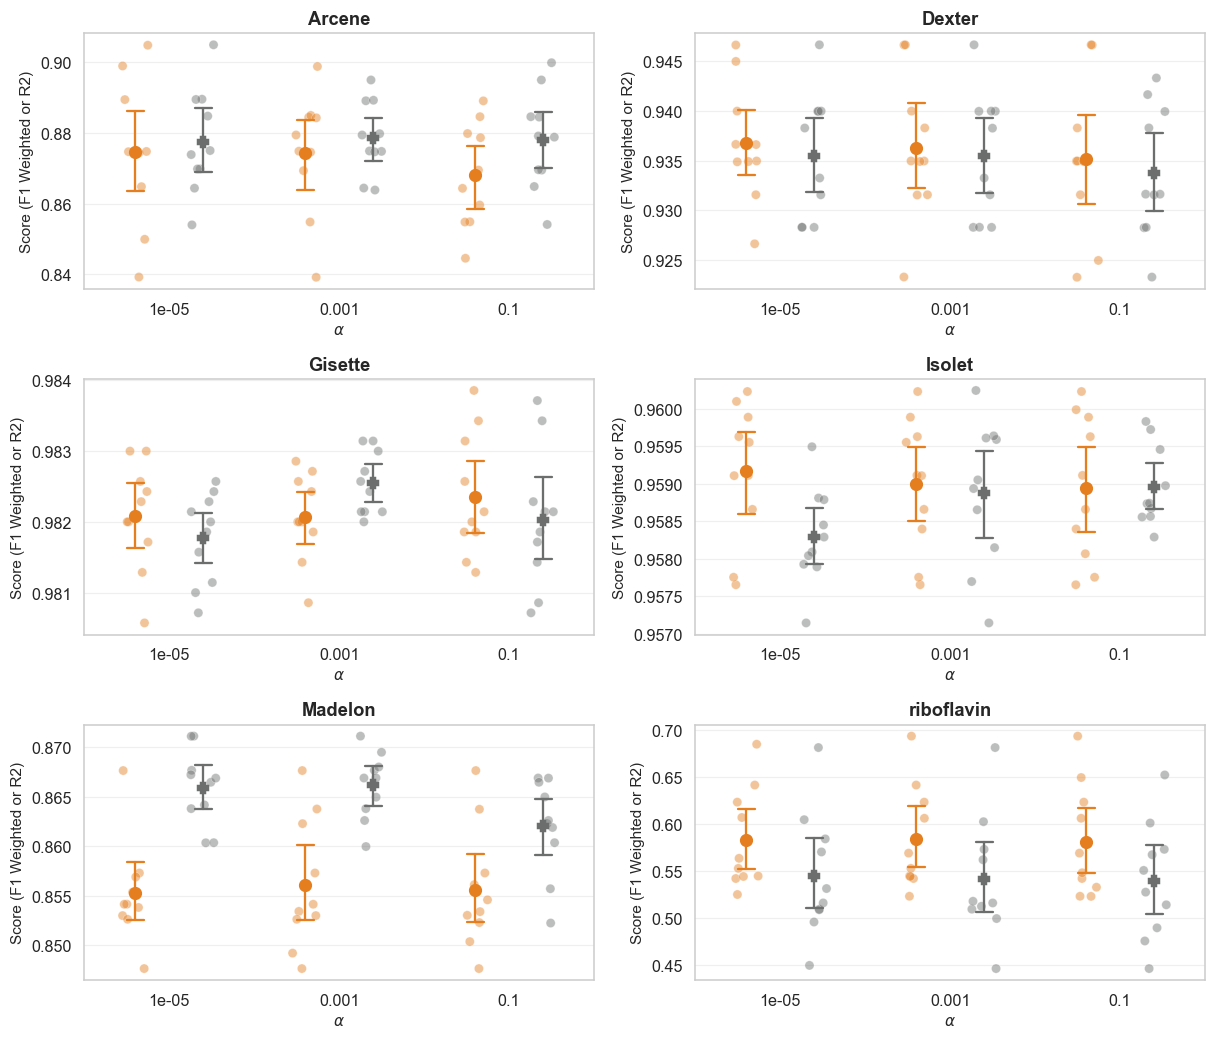

In [8]:
ar.plot_score_comparison(df_viz, estimator=TARGET_ESTIMATOR, figures_dir=figures_dir)

## 5. Runtime Distribution (Log Scale)

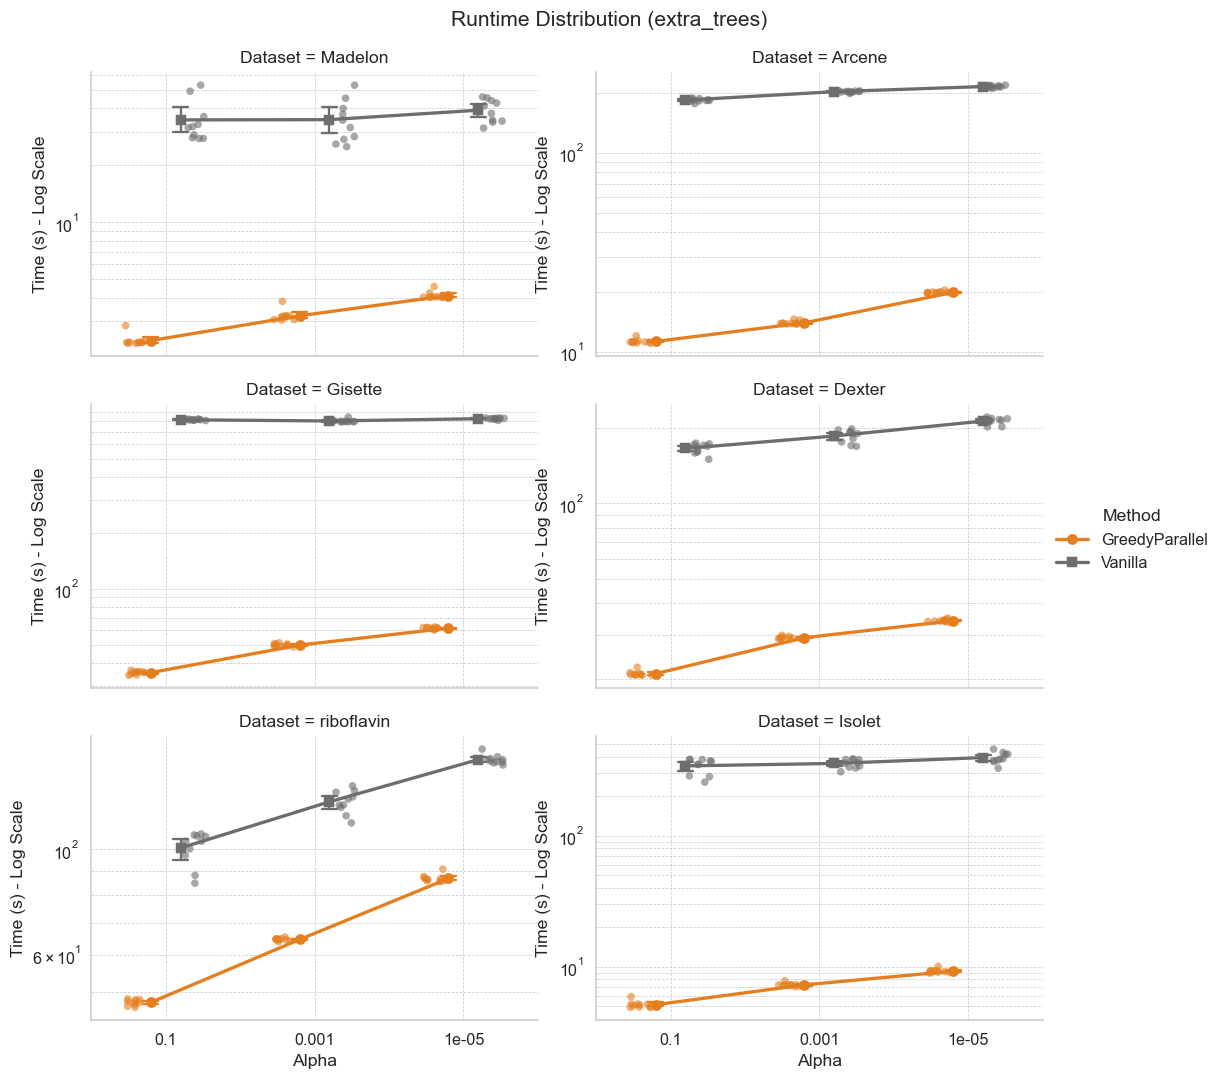

In [9]:
ar.plot_runtime_distribution(df_main, estimator=TARGET_ESTIMATOR, figures_dir=figures_dir)

## 6. Pareto Efficiency: Performance vs Cost

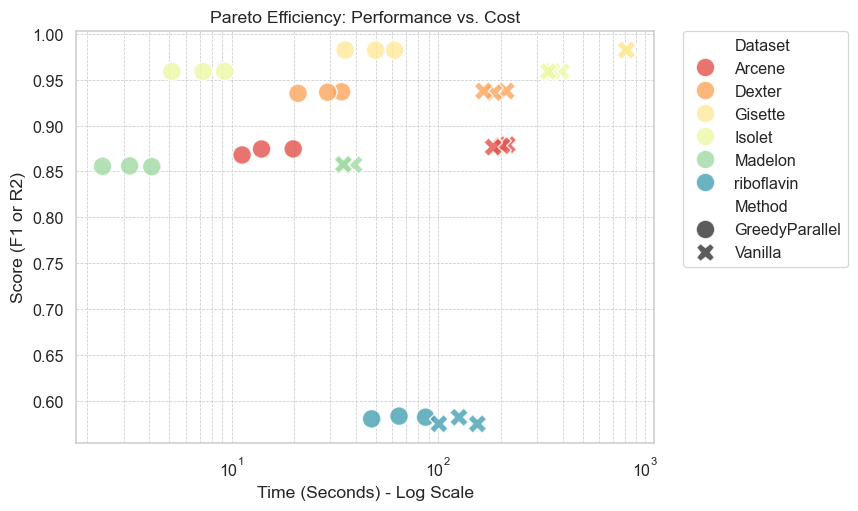

In [10]:
ar.plot_pareto_efficiency(df_main, estimator=TARGET_ESTIMATOR, figures_dir=figures_dir)

## 7. Computational Speedup (Vanilla / Greedy)

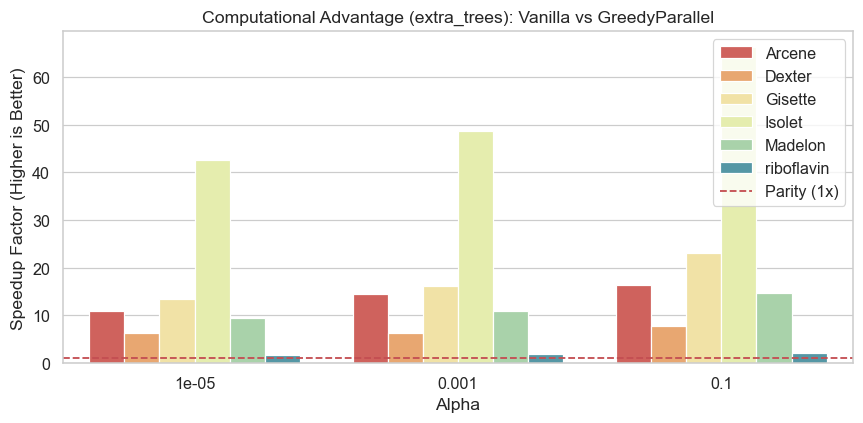

In [11]:
ar.plot_speedup(df_main, estimator=TARGET_ESTIMATOR, figures_dir=figures_dir)

---
# Part B — Checkpoint Convergence Analysis

## 8. Load Checkpoint Data

In [12]:
_, df_checkpoints = ar.load_data(
    main_file=MAIN_FILE,
    checkpoint_file=CHECKPOINT_FILE,
    estimator=TARGET_ESTIMATOR,
    max_time_sec=MAX_TIME_SEC,
)

df_greedy, greedy_label = ar.prepare_greedy(df_main)

datasets = sorted(df_checkpoints['Dataset'].unique())
alphas   = sorted(df_checkpoints['Alpha'].unique())

print(f'\nDatasets : {datasets}')
print(f'Alphas   : {alphas}')
print(f'Greedy variant: {greedy_label}')

Main results (extra_trees): 360 rows
Datasets : ['Arcene', 'Dexter', 'Gisette', 'Isolet', 'Madelon', 'riboflavin']
Methods  : ['GreedyParallel', 'Vanilla']
Alphas   : [1e-05, 0.001, 0.1]

Checkpoints (extra_trees): 10639 rows
Using GreedyParallel: 180 rows

Datasets : ['Arcene', 'Dexter', 'Gisette', 'Isolet', 'Madelon', 'riboflavin']
Alphas   : [1e-05, 0.001, 0.1]
Greedy variant: GreedyParallel


### Data Preview

In [13]:
print('Main Results:')
display(df_main.head())

print('\nCheckpoint History:')
display(df_checkpoints.head())

Main Results:


,Dataset,Task,n_samples,n_features_orig,Estimator,Method,Alpha,Run_ID,Time_Sec,Iterations,N_Confirmed,N_Tentative,Ratio_Selected,Score_Confirmed_Mean,Score_Confirmed_Std,Score_All_Mean,Score_All_Std
0,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,0,2.851742,-1,24,0,0.048,0.850364,0.014666,0.850364,0.014666
1,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,1,2.330664,-1,23,0,0.046,0.863749,0.022620,0.863749,0.022620
2,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,2,2.328686,-1,27,0,0.054,0.857301,0.014765,0.857301,0.014765
3,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,3,2.321240,-1,27,0,0.054,0.852286,0.008381,0.852286,0.008381
4,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,4,2.298126,-1,28,0,0.056,0.853394,0.013401,0.853394,0.013401



Checkpoint History:


,Dataset,Task,n_samples,n_features_orig,Estimator,Method,Alpha,Run_ID,Checkpoint_ID,Iteration,Elapsed_Sec,N_Confirmed,N_Tentative,N_Rejected,Score_Mean,Score_Std,Is_Final
0,Madelon,class,2600,500,extra_trees,Vanilla,0.1,0,0,1,0.467042,0,500,0,0.000000,0.000000,False
1,Madelon,class,2600,500,extra_trees,Vanilla,0.1,0,1,13,6.068012,13,14,473,0.847253,0.020492,False
2,Madelon,class,2600,500,extra_trees,Vanilla,0.1,0,2,21,6.951089,14,13,473,0.862664,0.008014,False
3,Madelon,class,2600,500,extra_trees,Vanilla,0.1,0,3,24,7.302092,16,11,473,0.855748,0.014982,False
4,Madelon,class,2600,500,extra_trees,Vanilla,0.1,0,4,33,8.284693,17,10,473,0.870373,0.007553,False


## 9. Convergence: Performance vs Time

For each dataset, one subplot per alpha. Each line = one Vanilla run.
Dashed red = Greedy mean. Dotted red vertical = Greedy mean runtime.

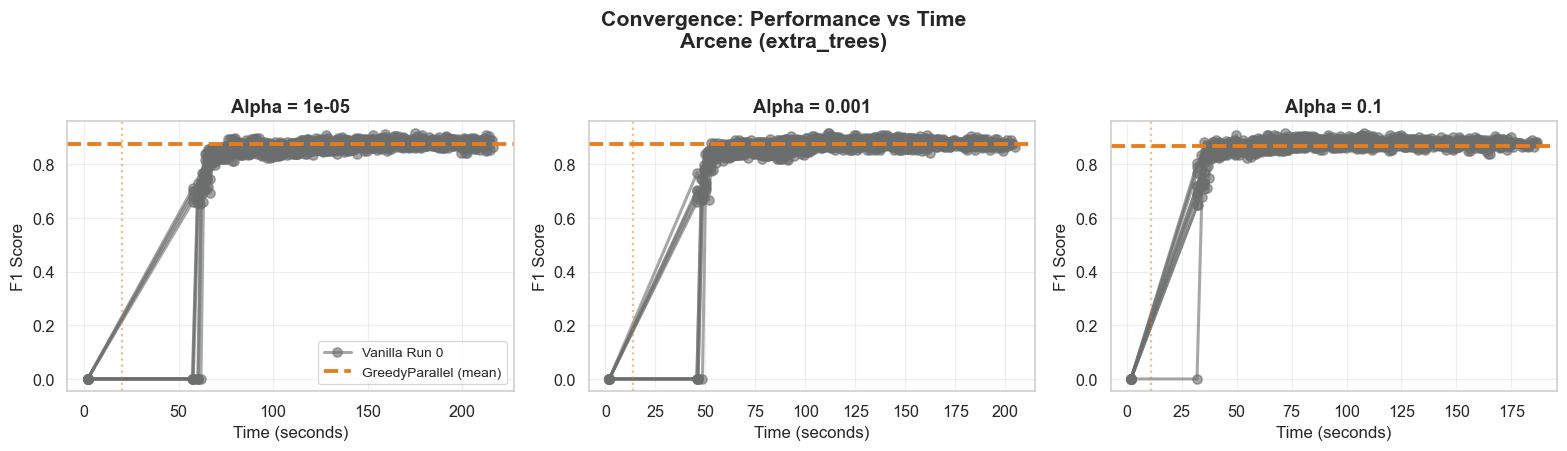

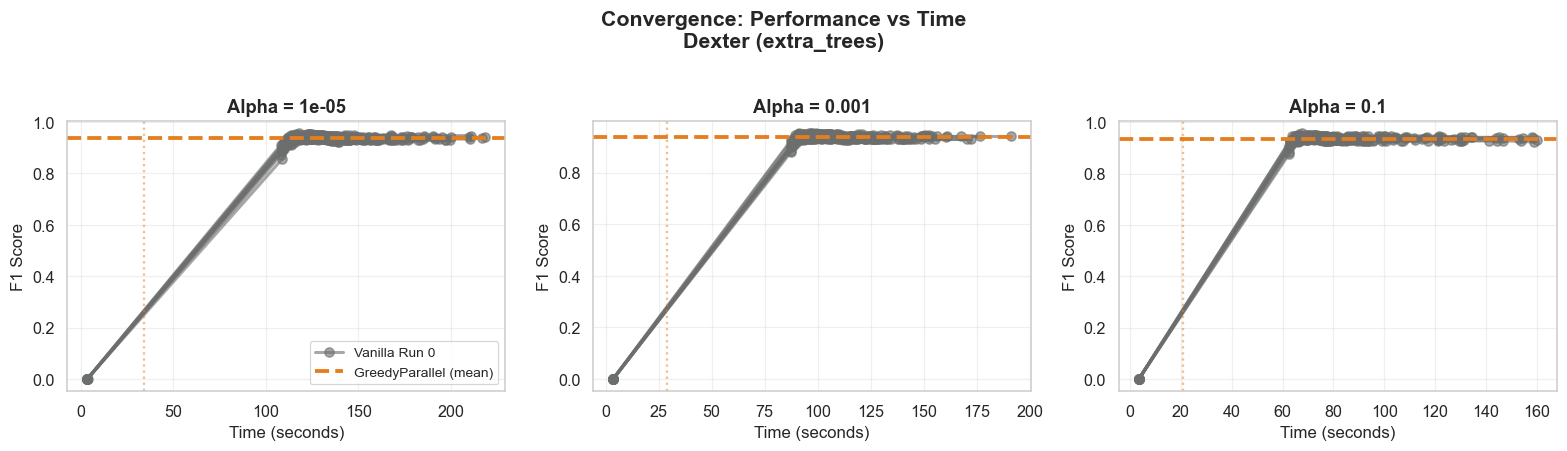

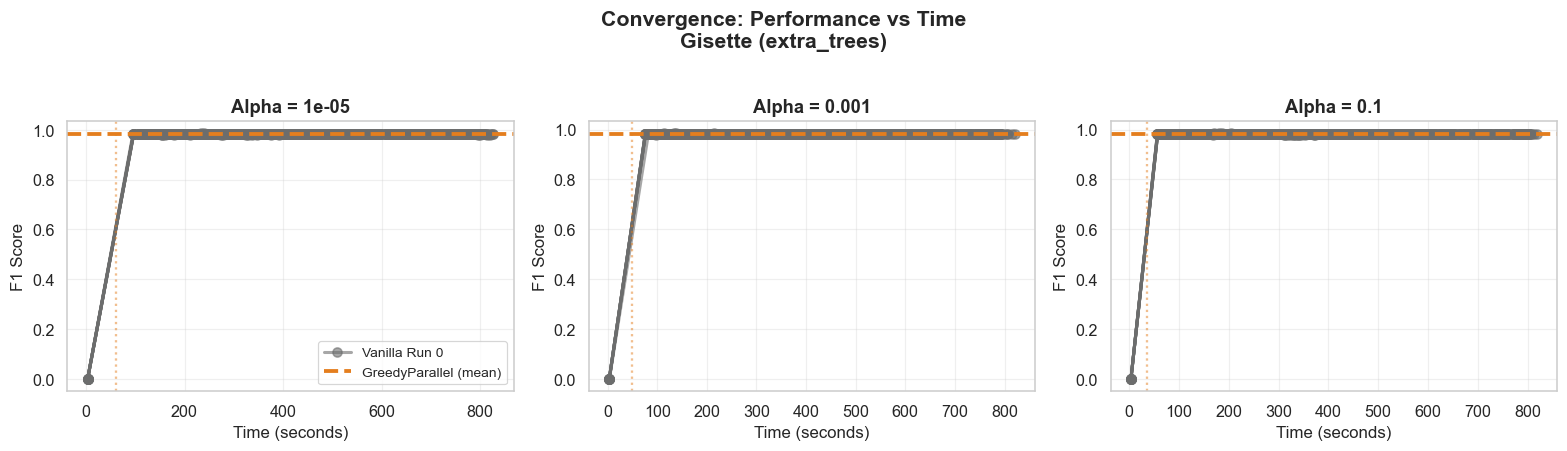

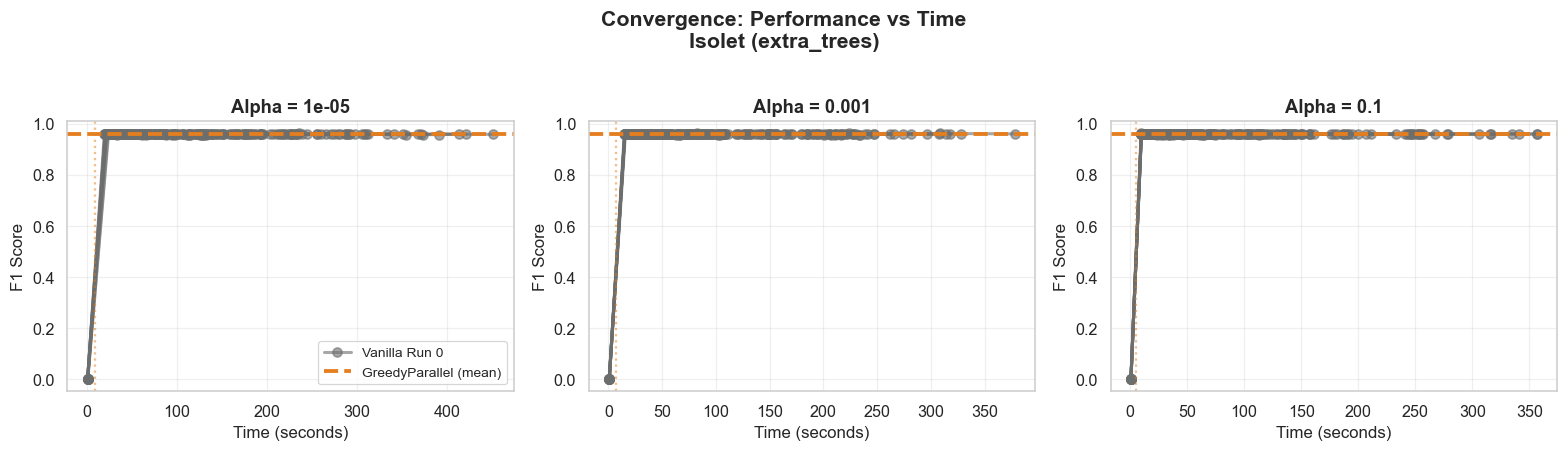

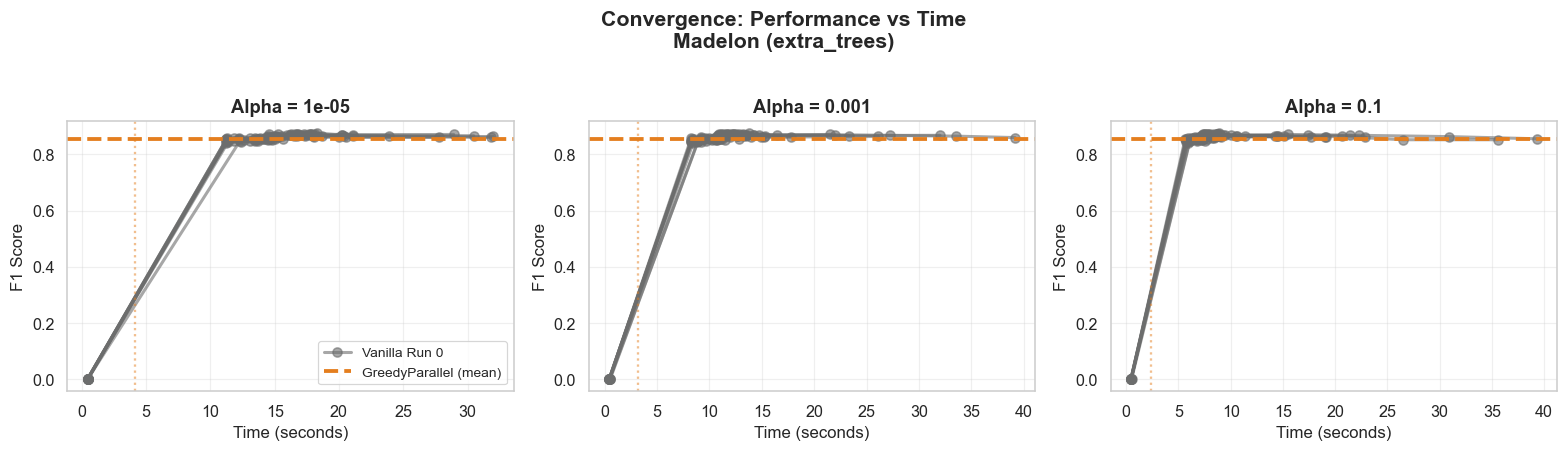

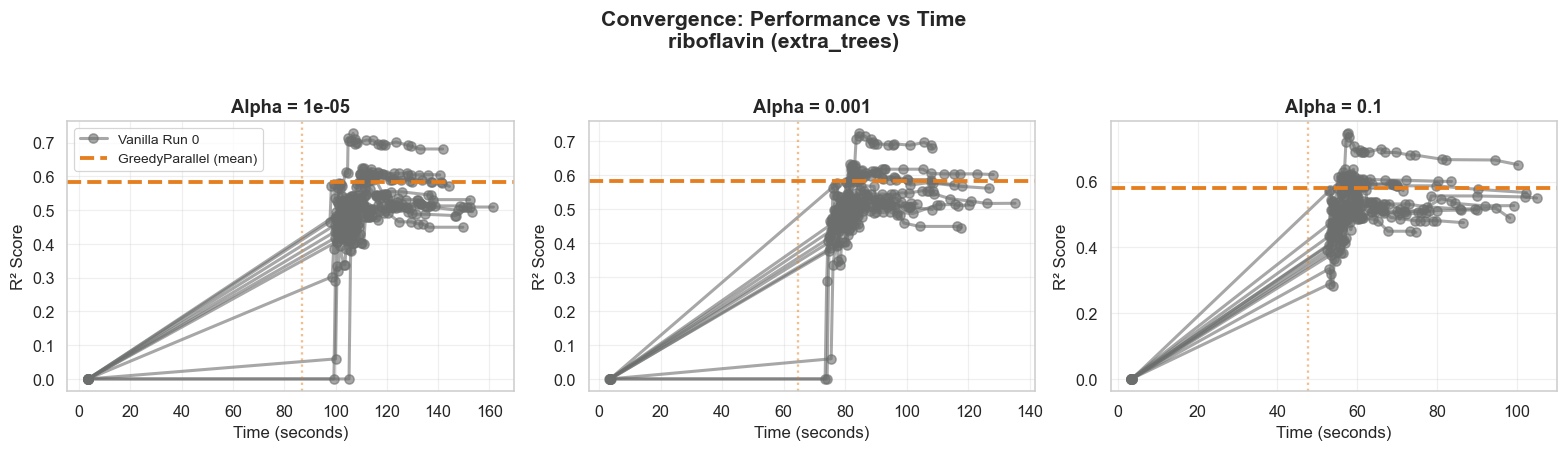

In [14]:
for dataset in datasets:
    ar.plot_convergence_vs_time(
        dataset=dataset,
        estimator=TARGET_ESTIMATOR,
        df_checkpoints=df_checkpoints,
        df_greedy=df_greedy,
        alphas=alphas,
        greedy_label=greedy_label,
        figures_dir=figures_dir,        
    )

## 10. Convergence: Performance vs Iteration

Same layout as above but X-axis shows iteration count.

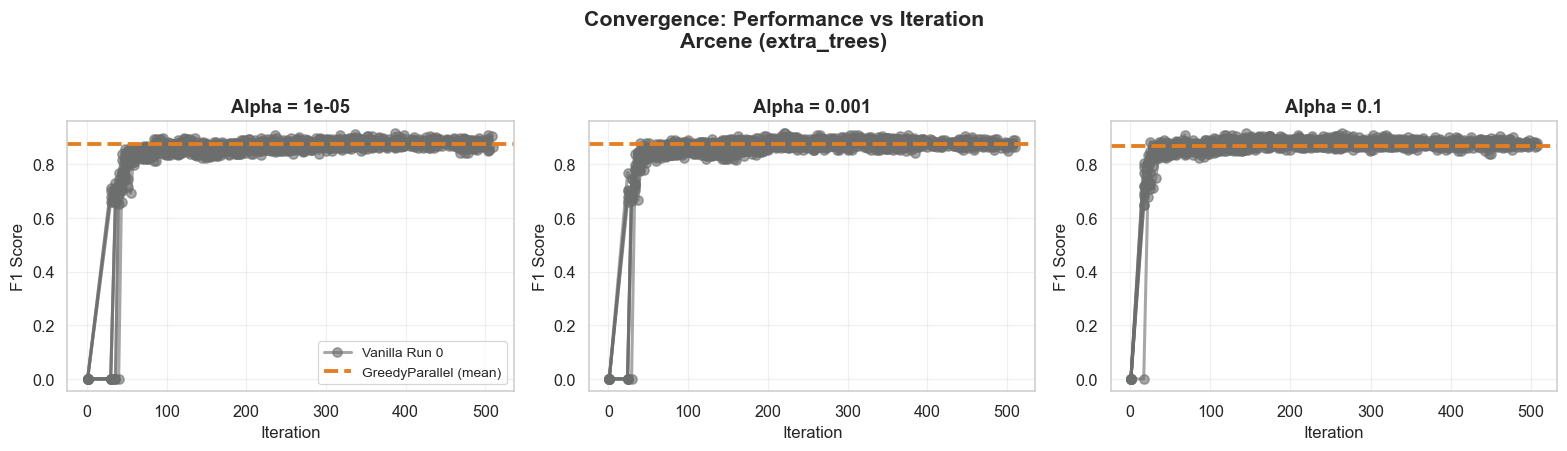

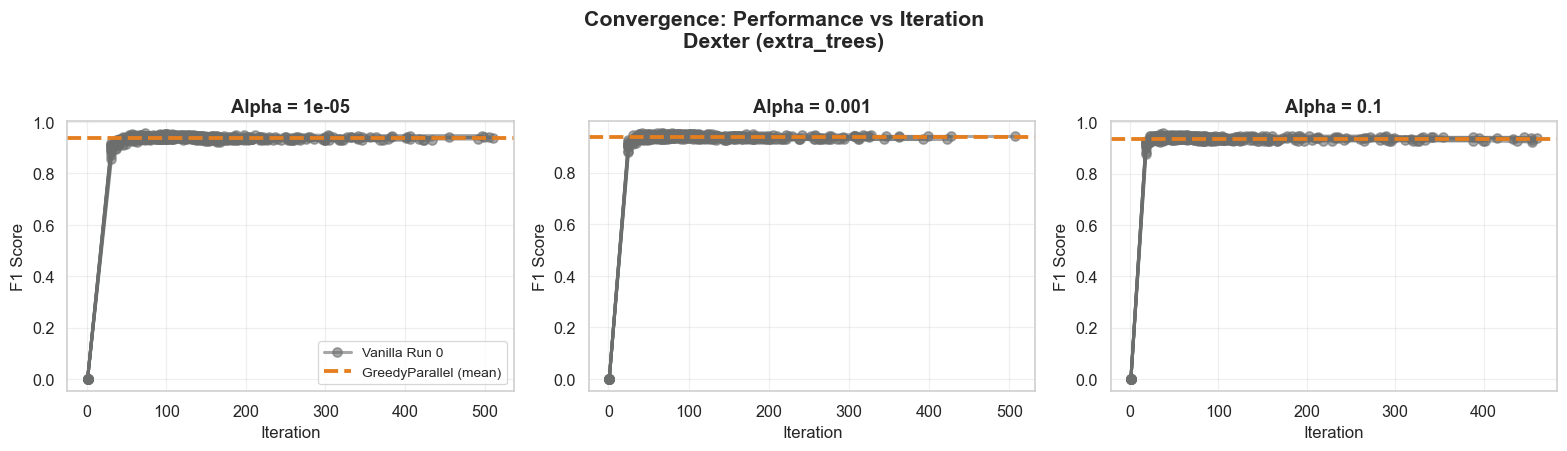

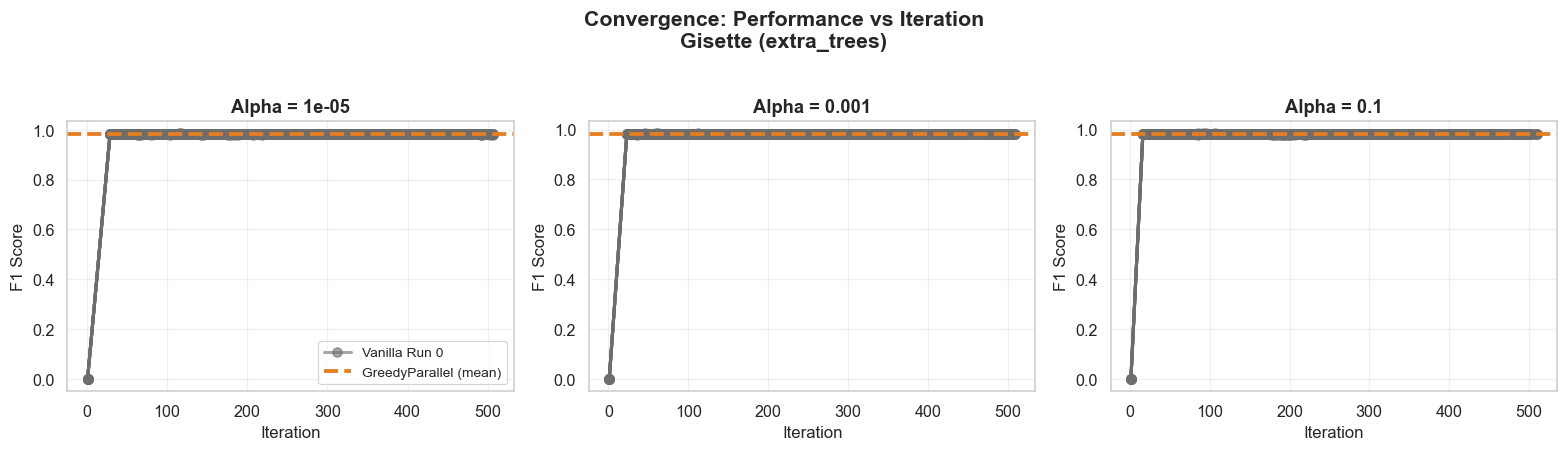

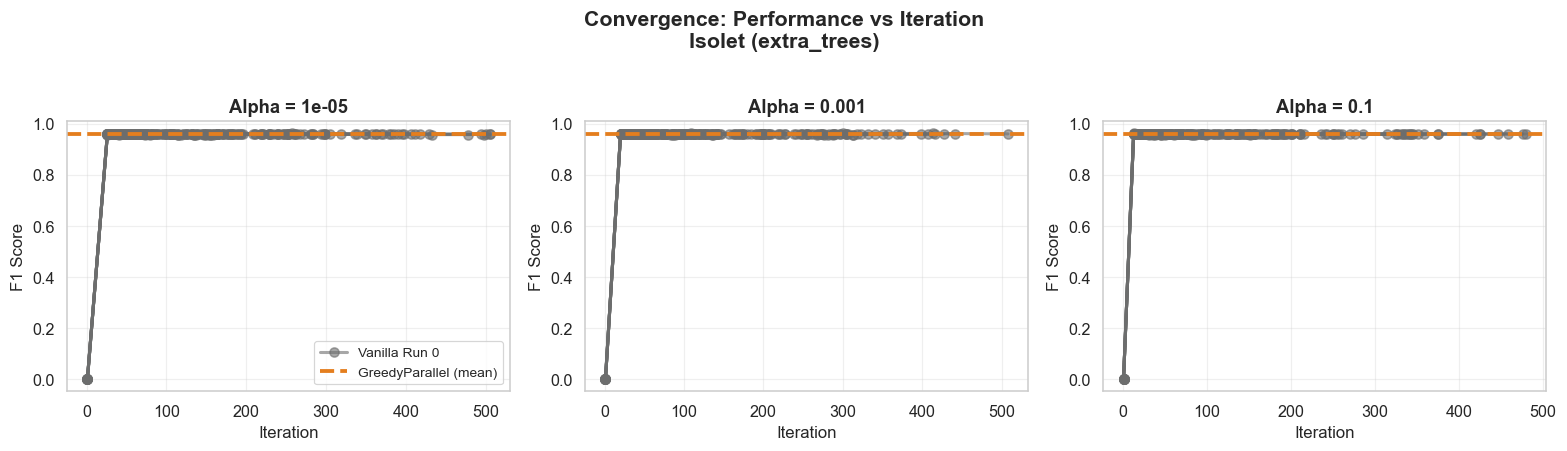

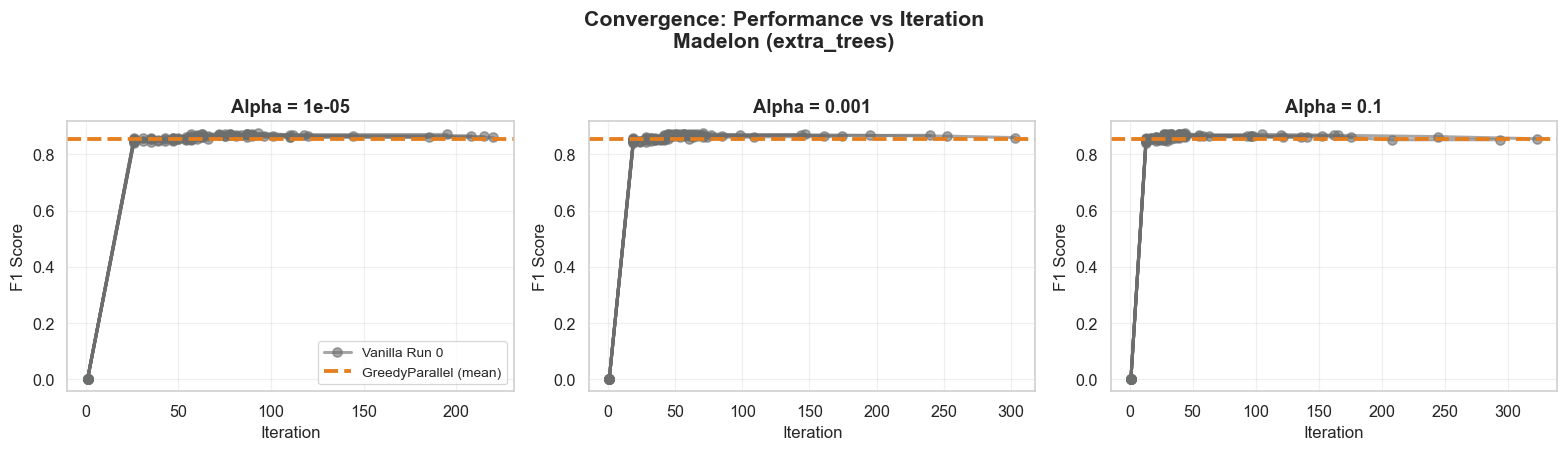

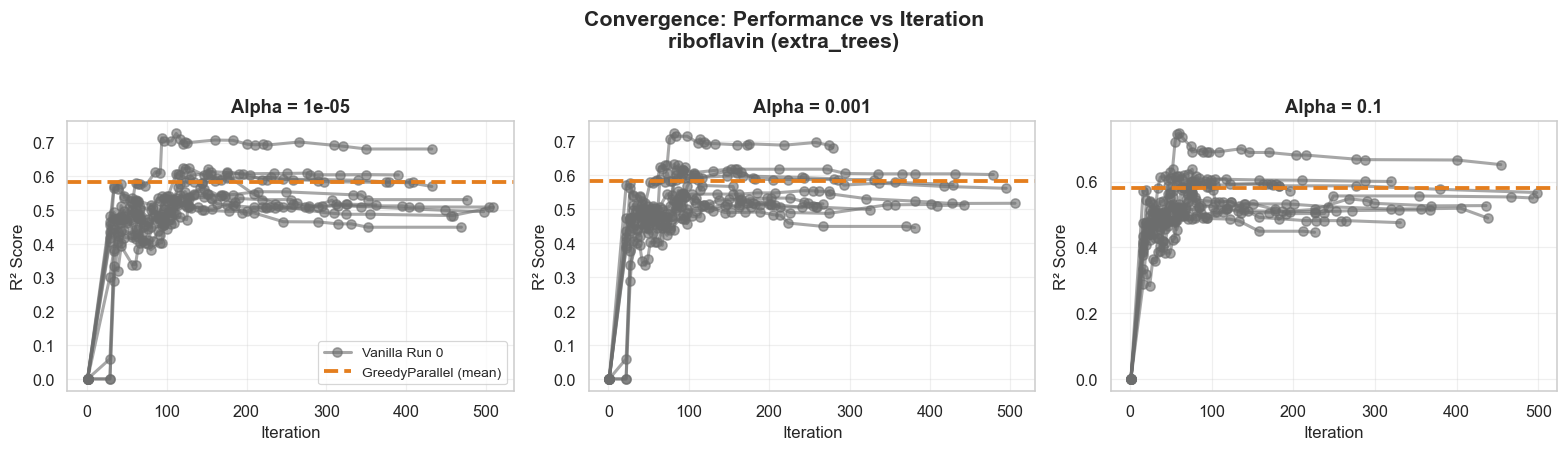

In [15]:
for dataset in datasets:
    ar.plot_convergence_vs_iteration(
        dataset=dataset,
        estimator=TARGET_ESTIMATOR,
        df_checkpoints=df_checkpoints,
        df_greedy=df_greedy,
        alphas=alphas,
        greedy_label=greedy_label,
        figures_dir=figures_dir,
    )

## 11. Undecidedness Factor

Proportion of Tentative features over all features (Tentative / Total).
Lower = more features have been decided.

Undecidedness Factor vs Iteration


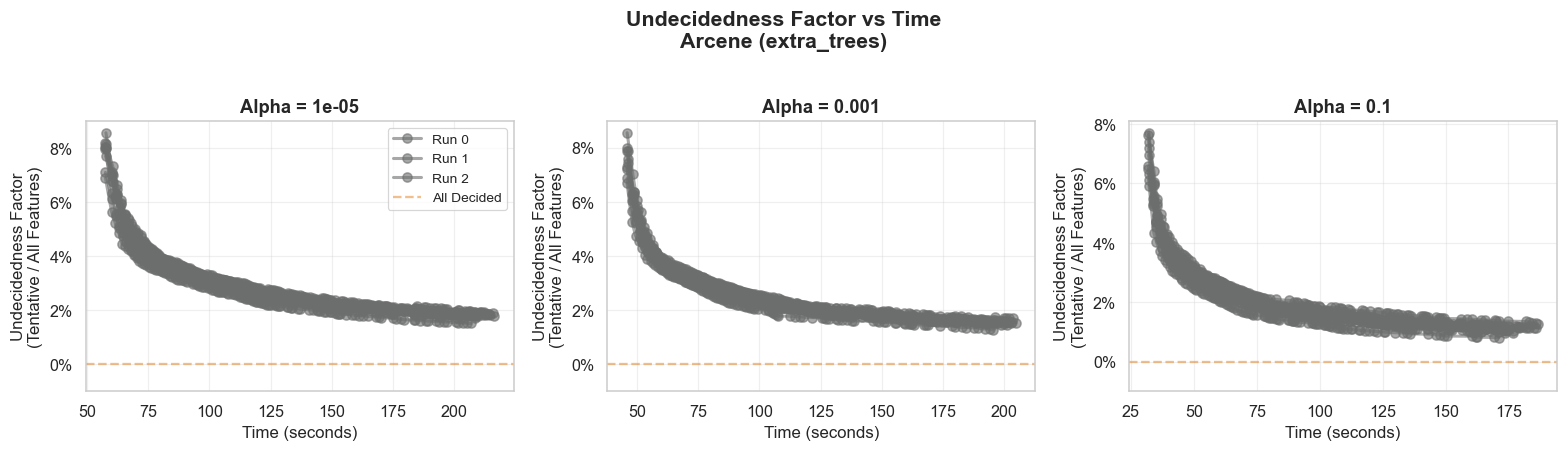

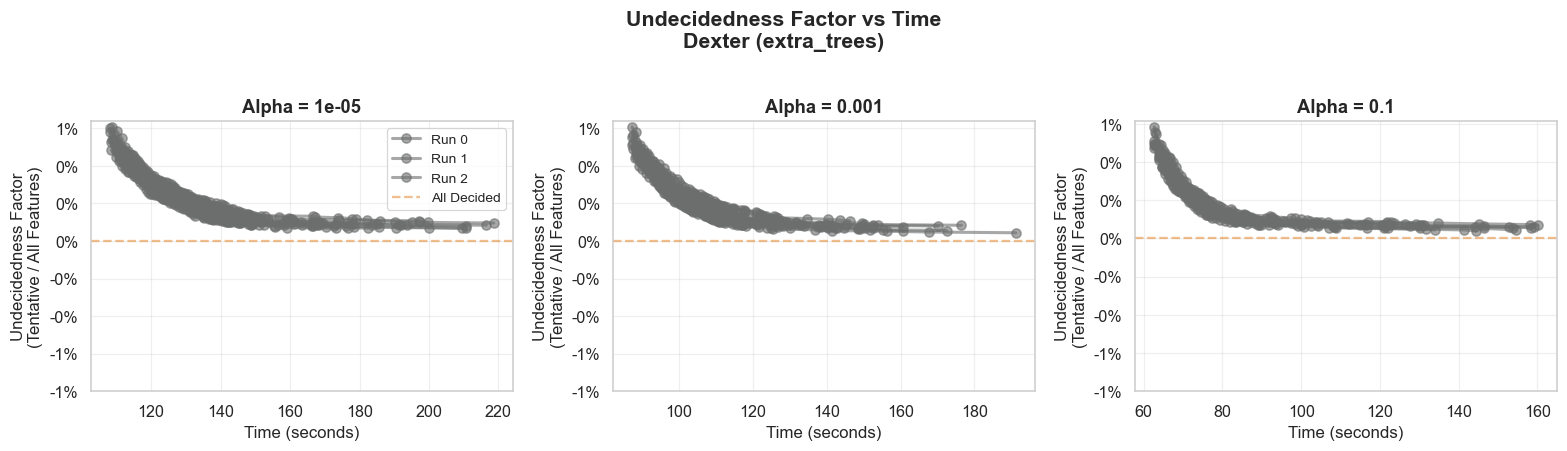

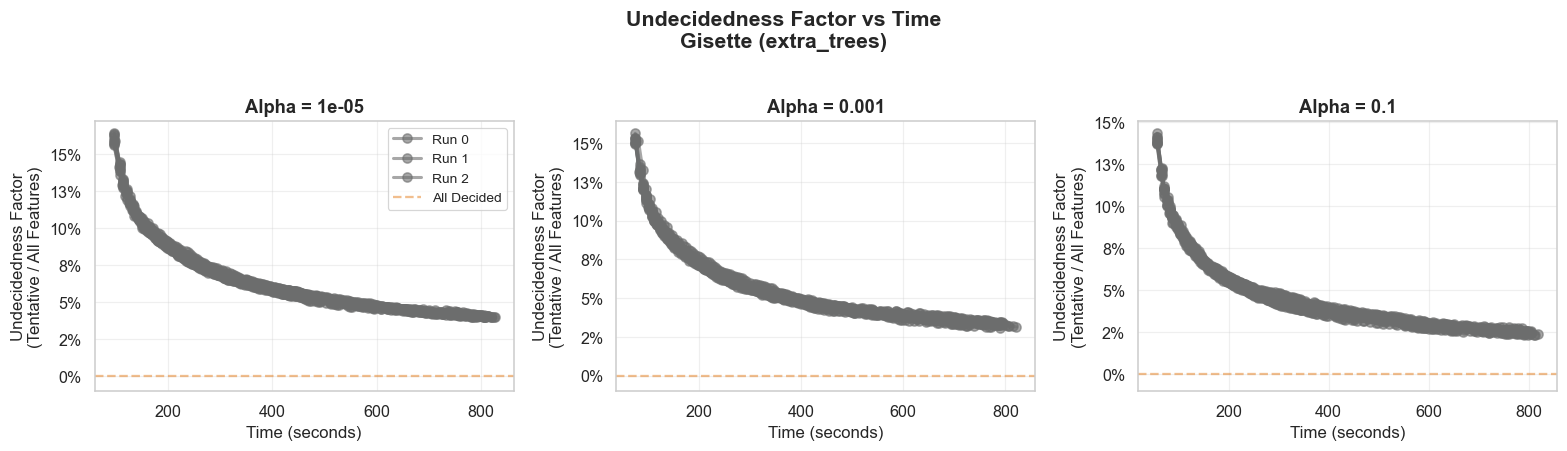

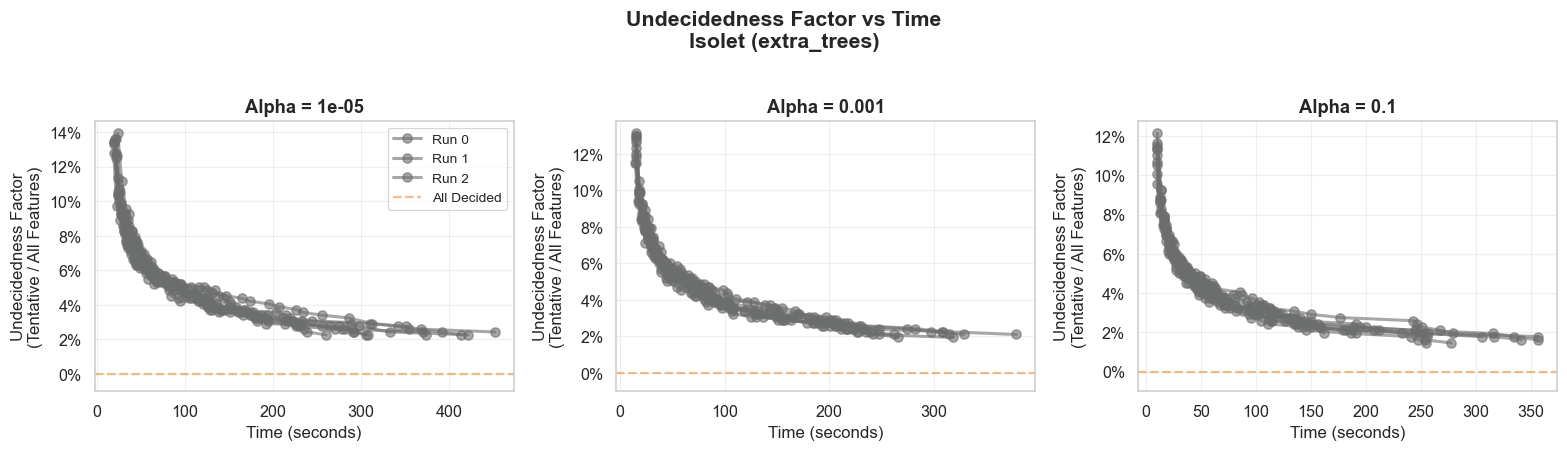

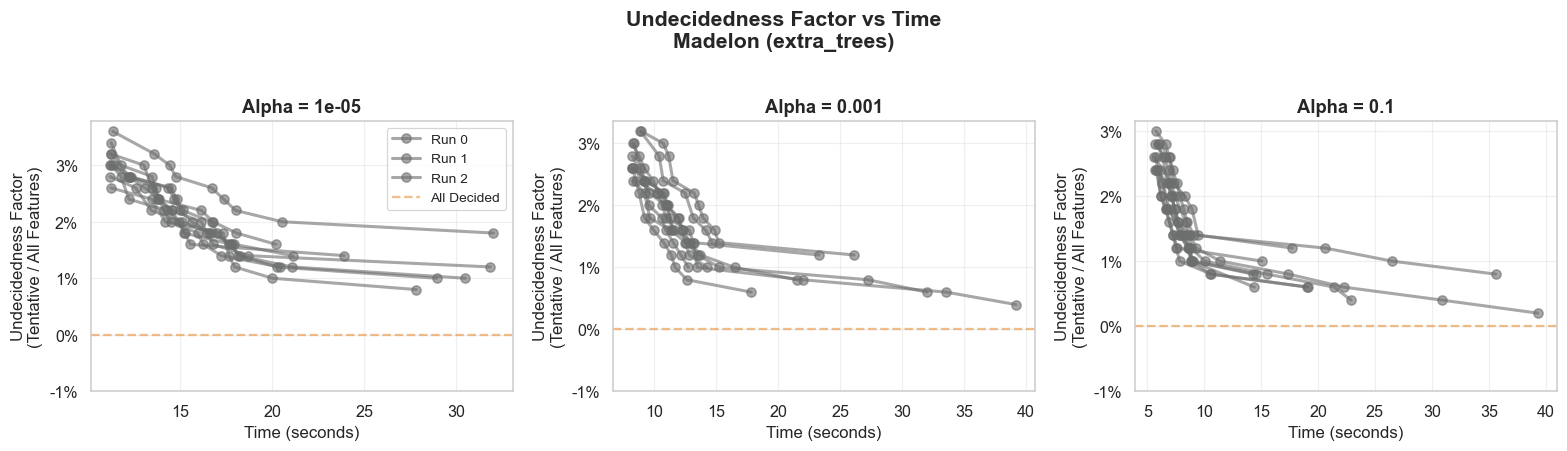

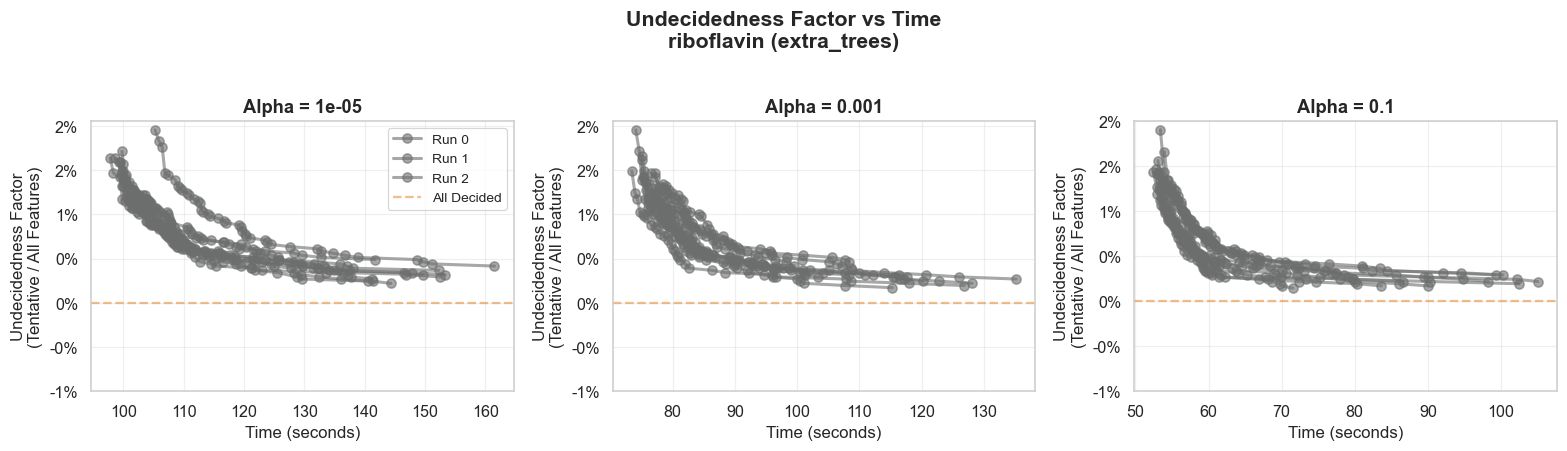

In [16]:
print('Undecidedness Factor vs Iteration')
for dataset in datasets:
    ar.plot_undecidedness_factor(
        dataset=dataset,
        estimator=TARGET_ESTIMATOR,
        df_checkpoints=df_checkpoints,
        alphas=alphas,
        x_axis='time',
        figures_dir=figures_dir,
    )

Undecidedness Factor vs Iteration


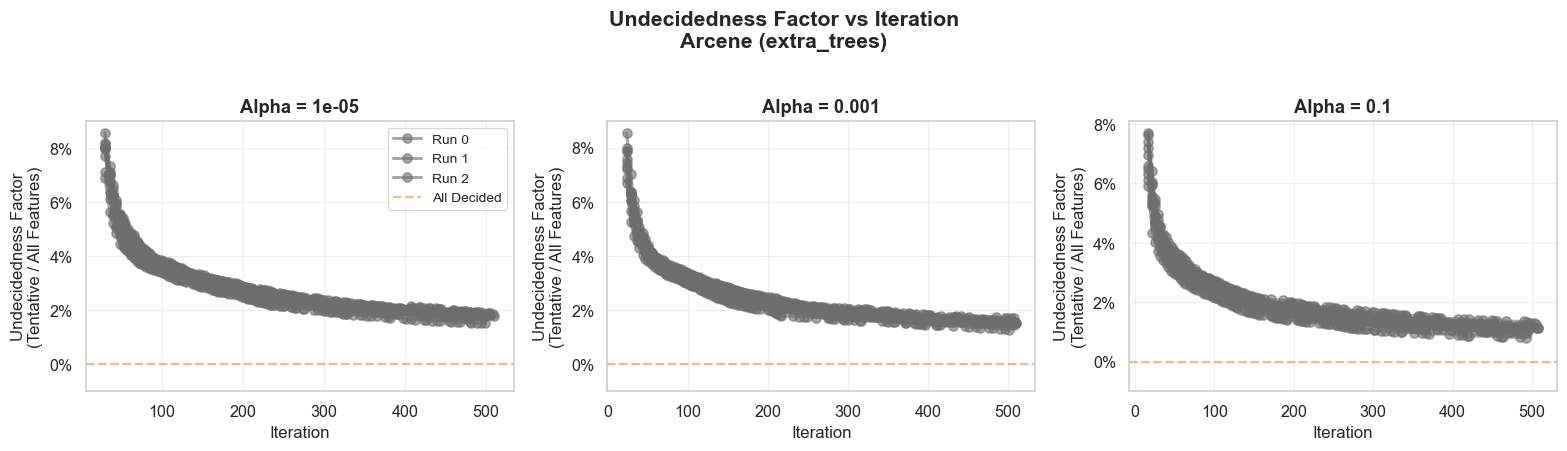

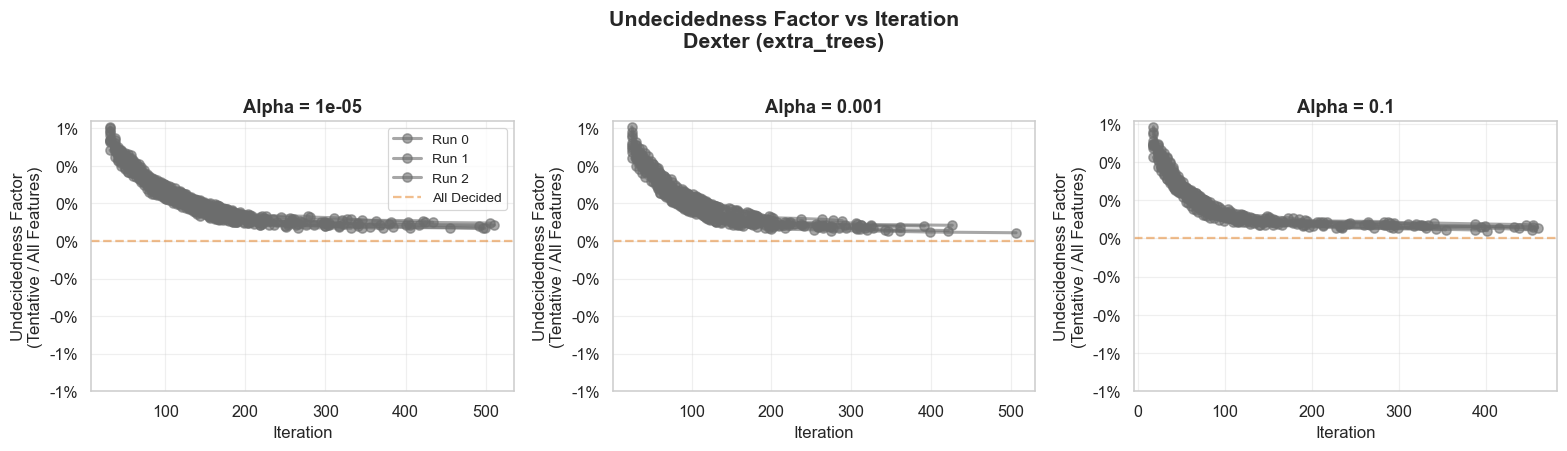

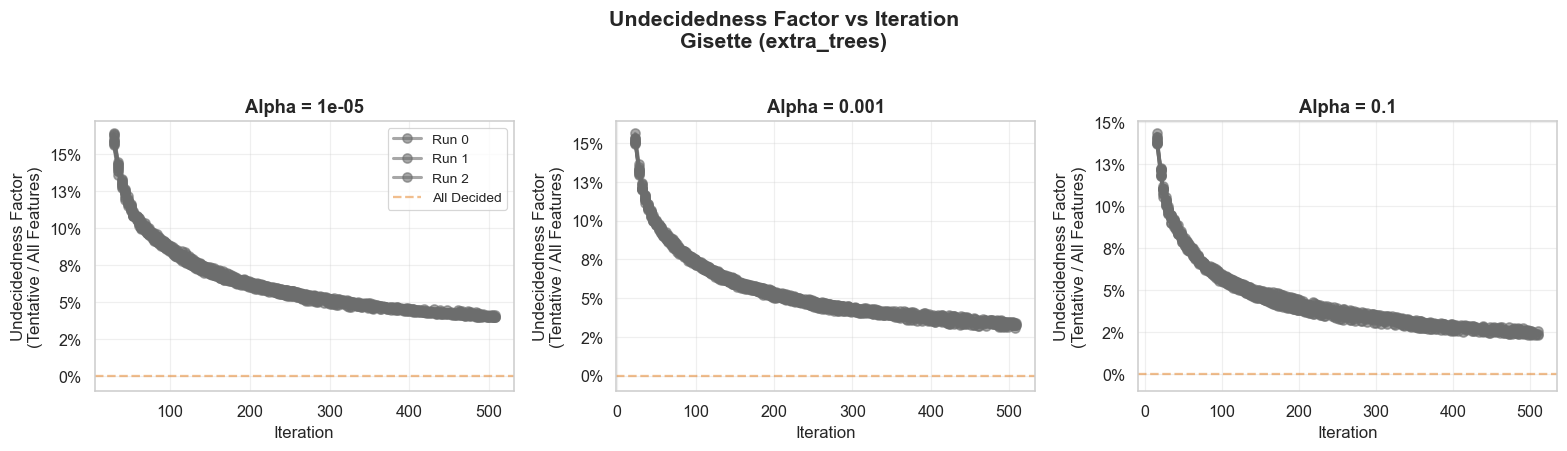

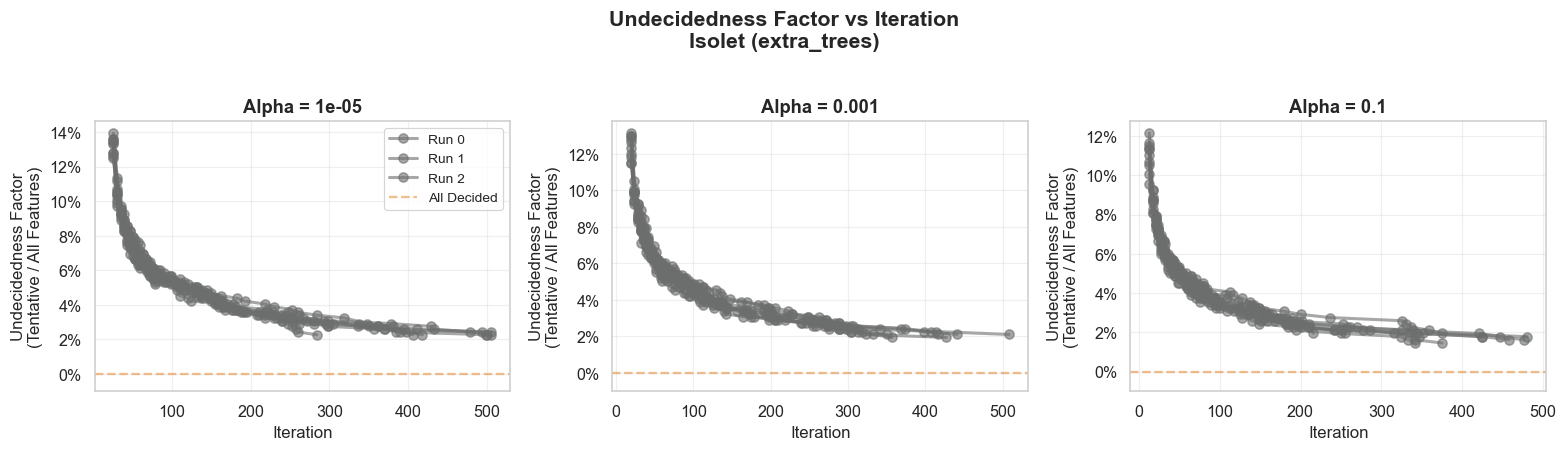

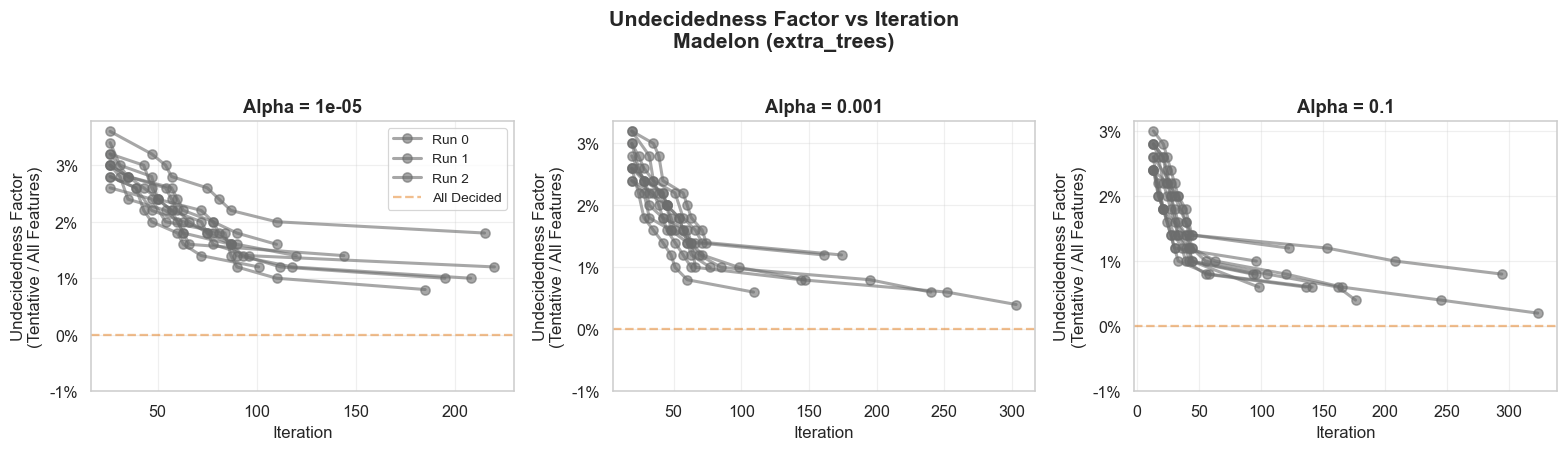

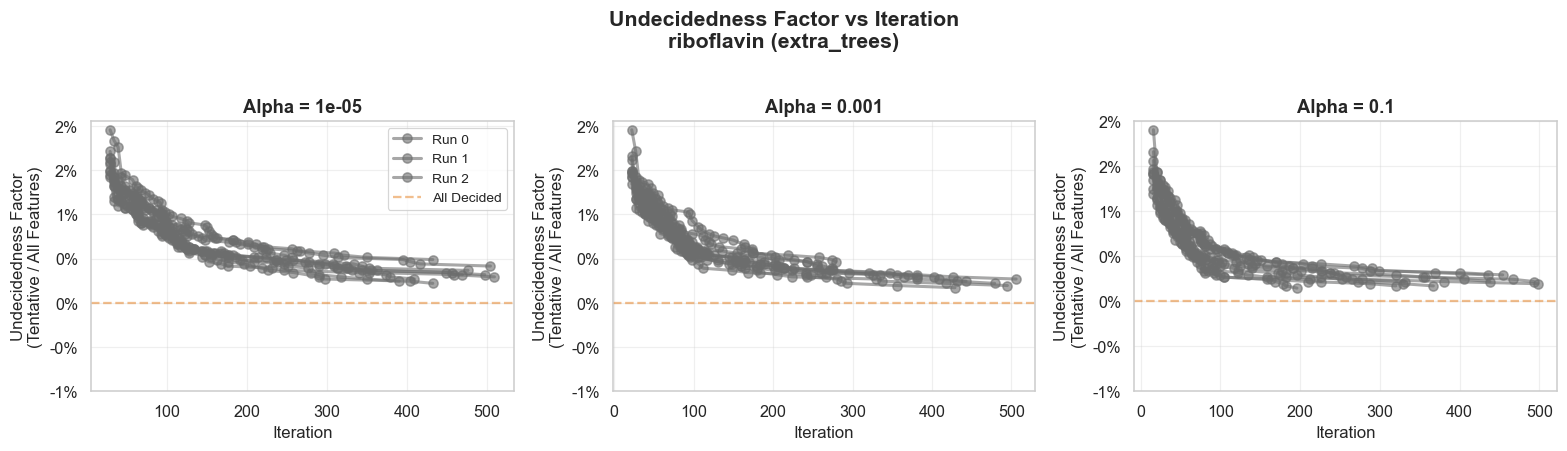

In [17]:
print('Undecidedness Factor vs Iteration')
for dataset in datasets:
    ar.plot_undecidedness_factor(
        dataset=dataset,
        estimator=TARGET_ESTIMATOR,
        df_checkpoints=df_checkpoints,
        alphas=alphas,
        x_axis='iteration',
        figures_dir=figures_dir,
    )

## 12. Potential Miss Rate

Proportion of selected features that are still Tentative: Tentative / (Tentative + Confirmed).
A high rate means many selected features are not yet confirmed.

Potential Miss Rate vs Time


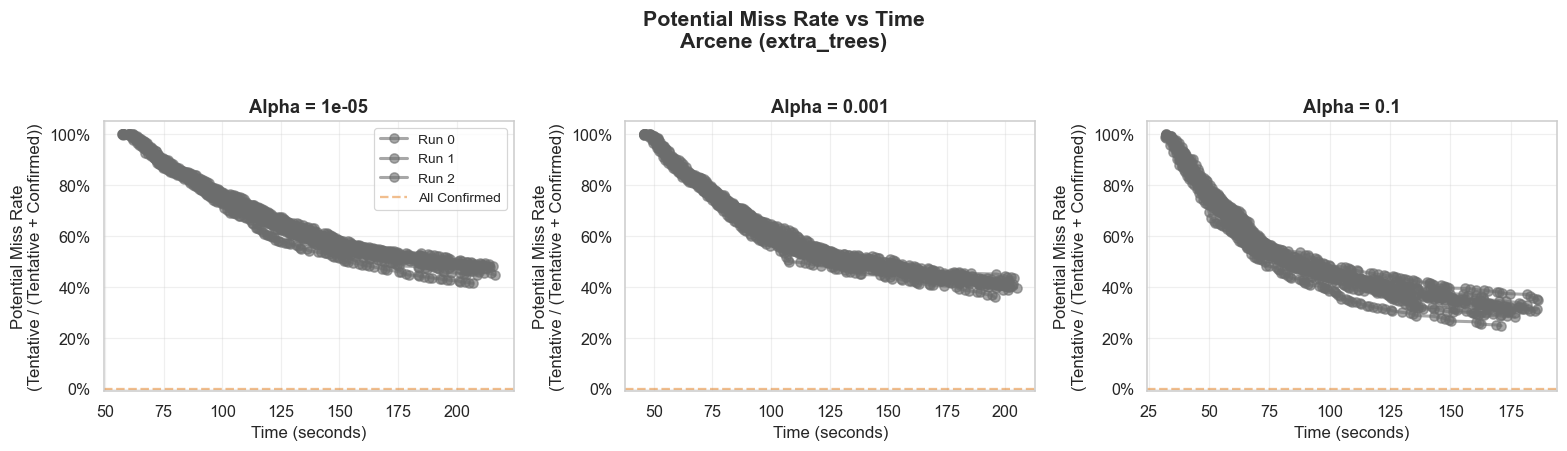

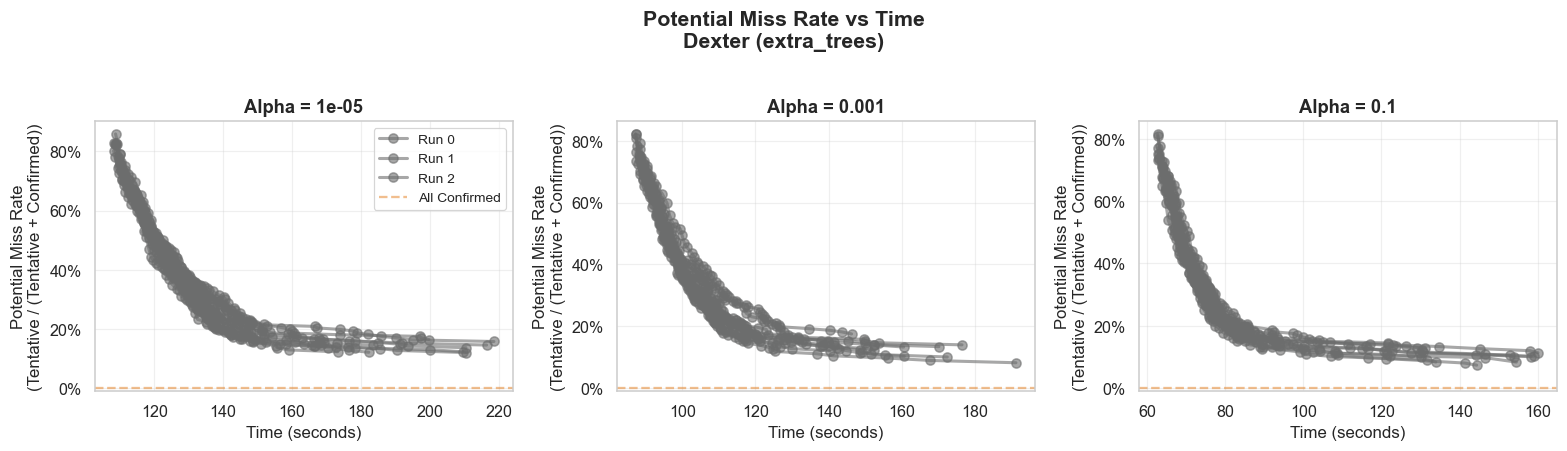

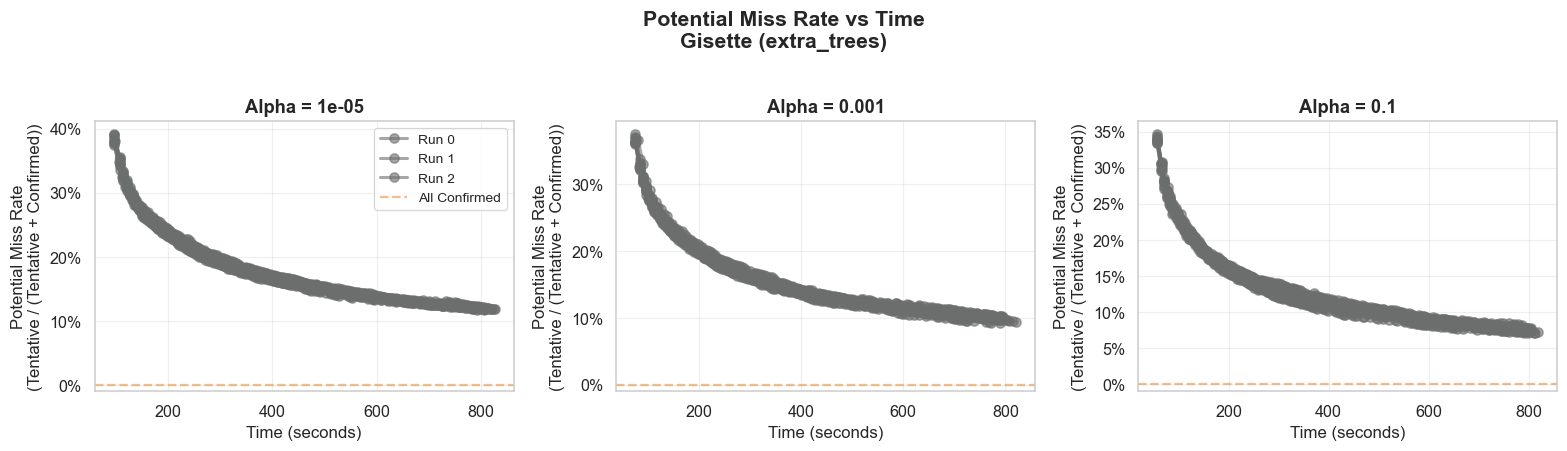

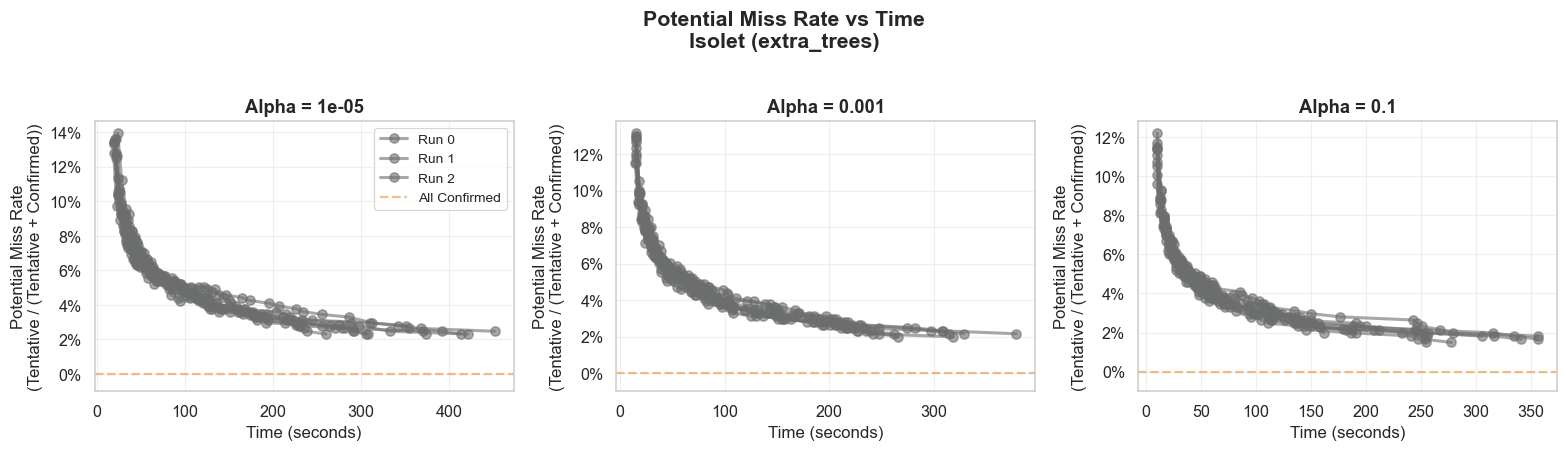

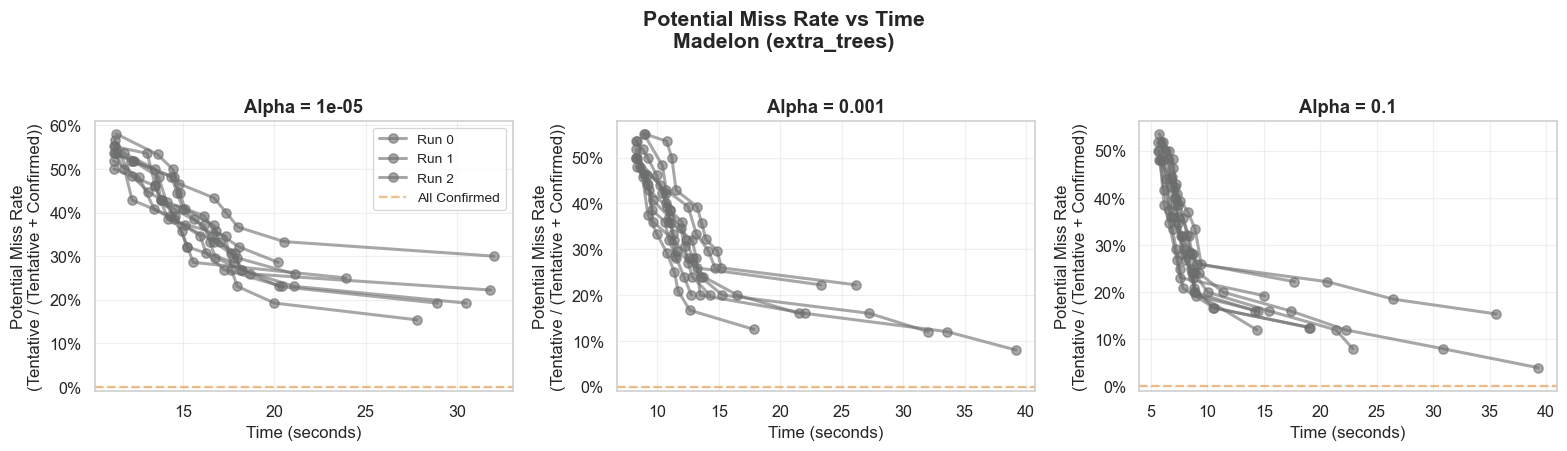

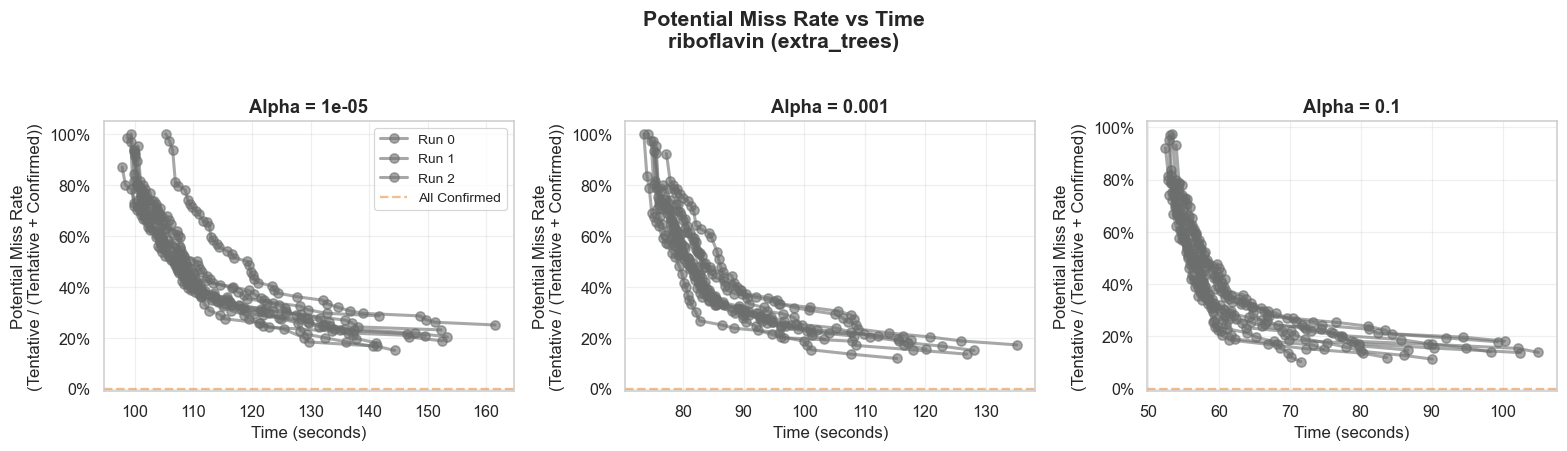

In [18]:
print('Potential Miss Rate vs Time')
for dataset in datasets:
    ar.plot_potential_miss_rate(
        dataset=dataset,
        estimator=TARGET_ESTIMATOR,
        df_checkpoints=df_checkpoints,
        alphas=alphas,
        x_axis='time',
        figures_dir=figures_dir,
    )

Potential Miss Rate vs Iteration


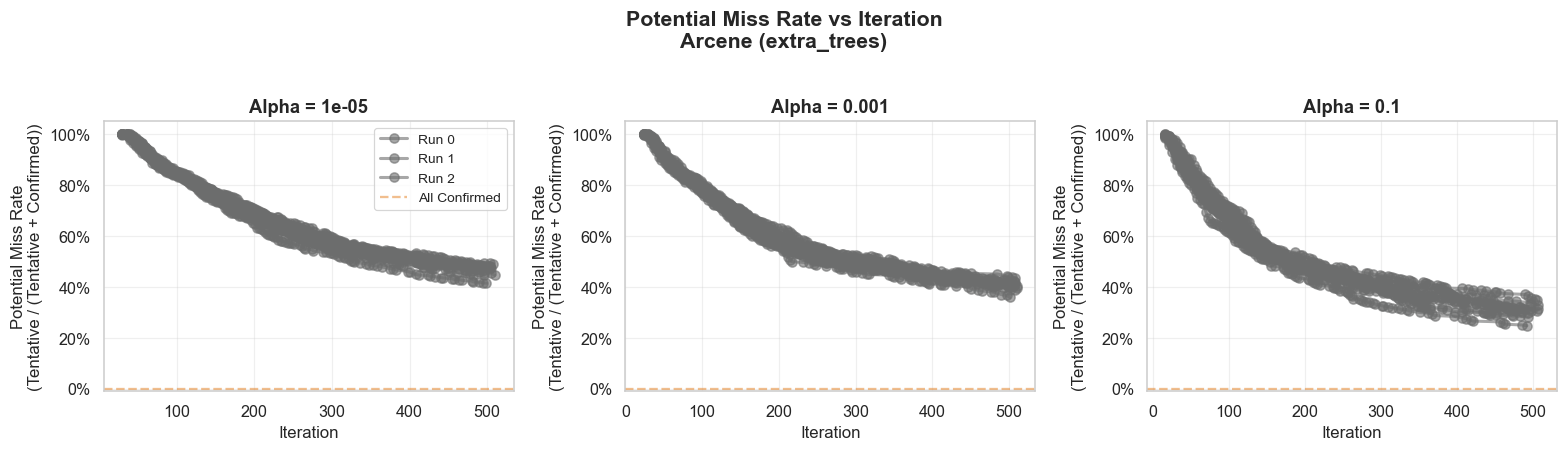

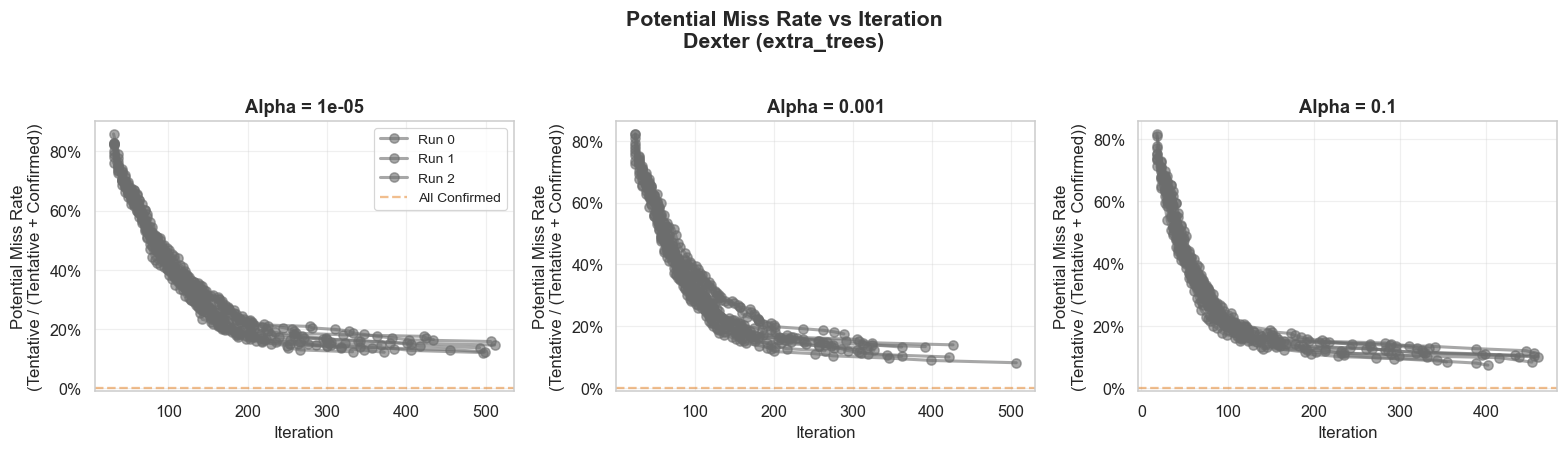

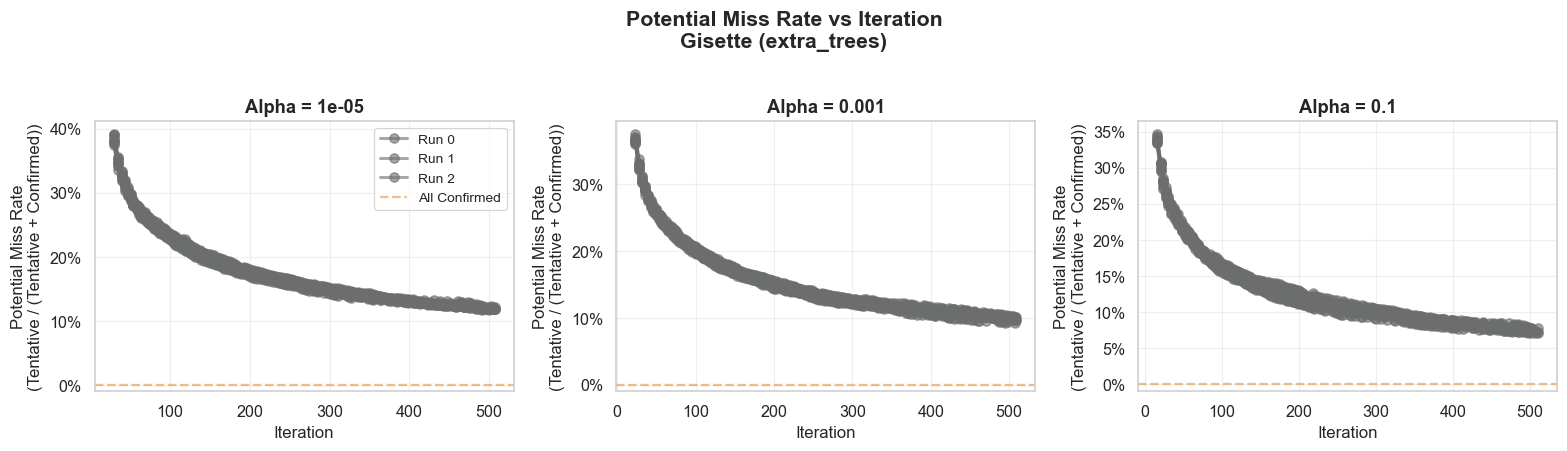

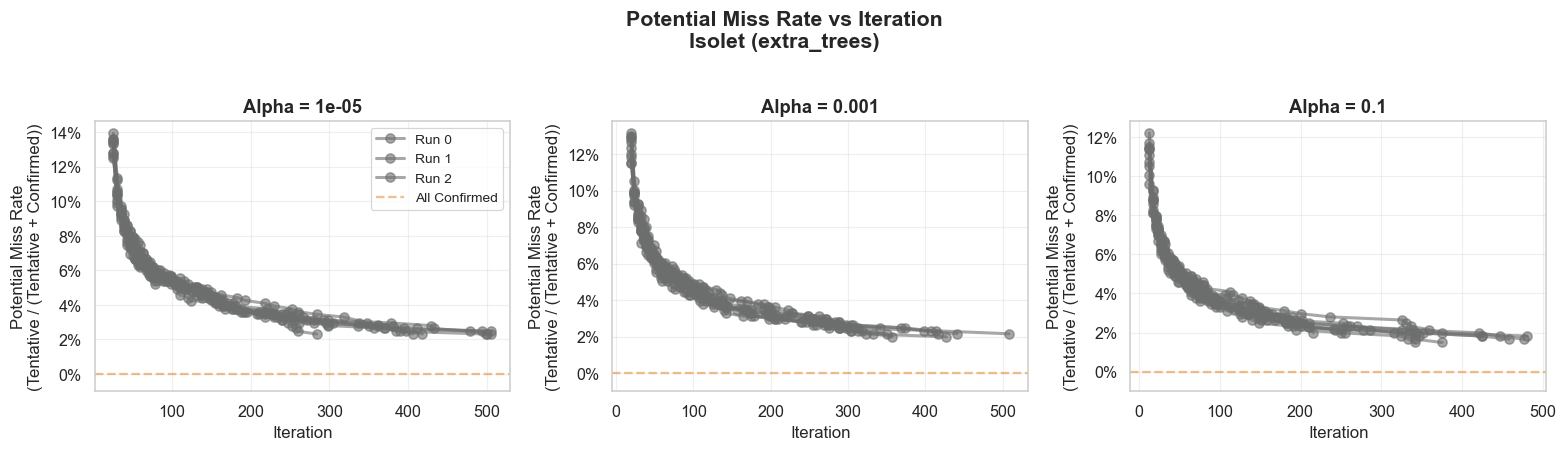

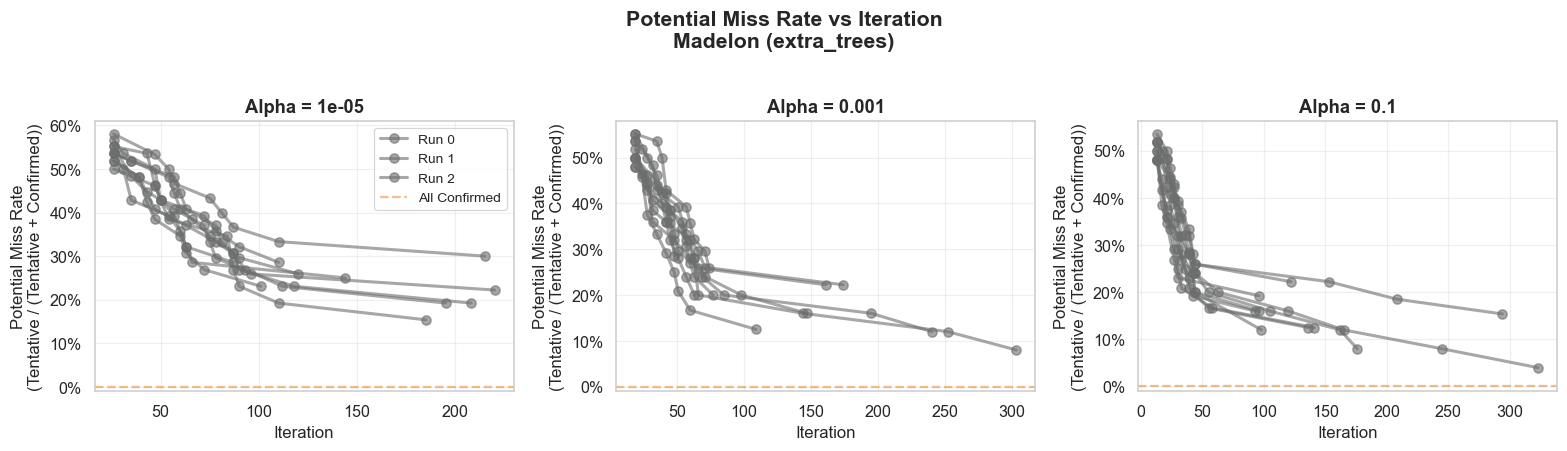

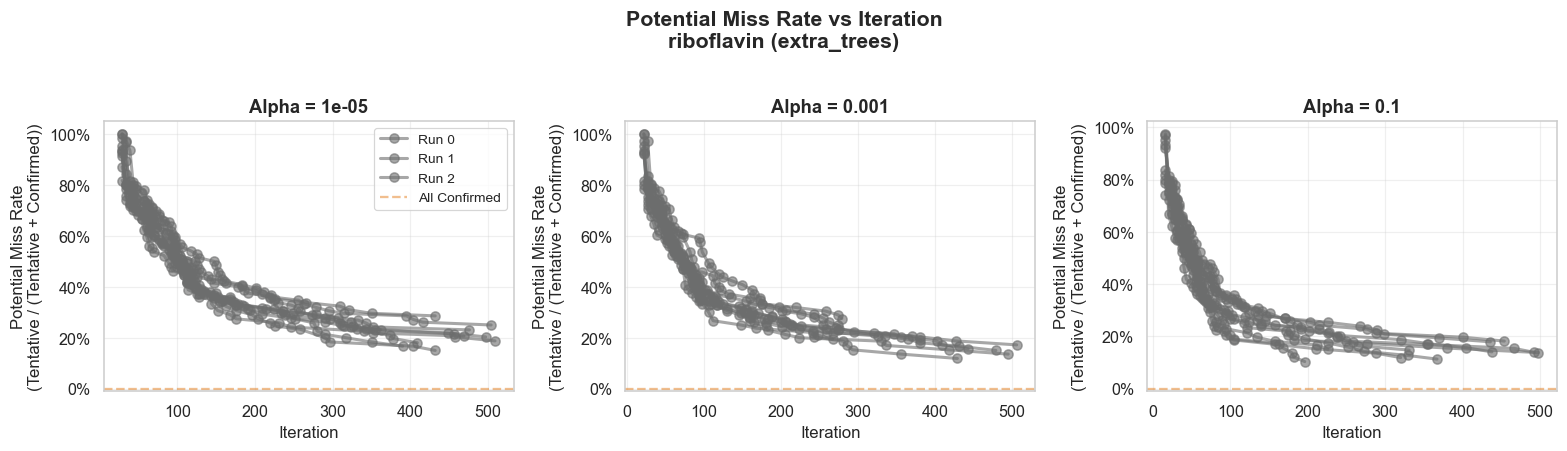

In [19]:
print('Potential Miss Rate vs Iteration')
for dataset in datasets:
    ar.plot_potential_miss_rate(
        dataset=dataset,
        estimator=TARGET_ESTIMATOR,
        df_checkpoints=df_checkpoints,
        alphas=alphas,
        x_axis='iteration',
        figures_dir=figures_dir,
    )

# Potential Miss Rate and Undecidness Factor

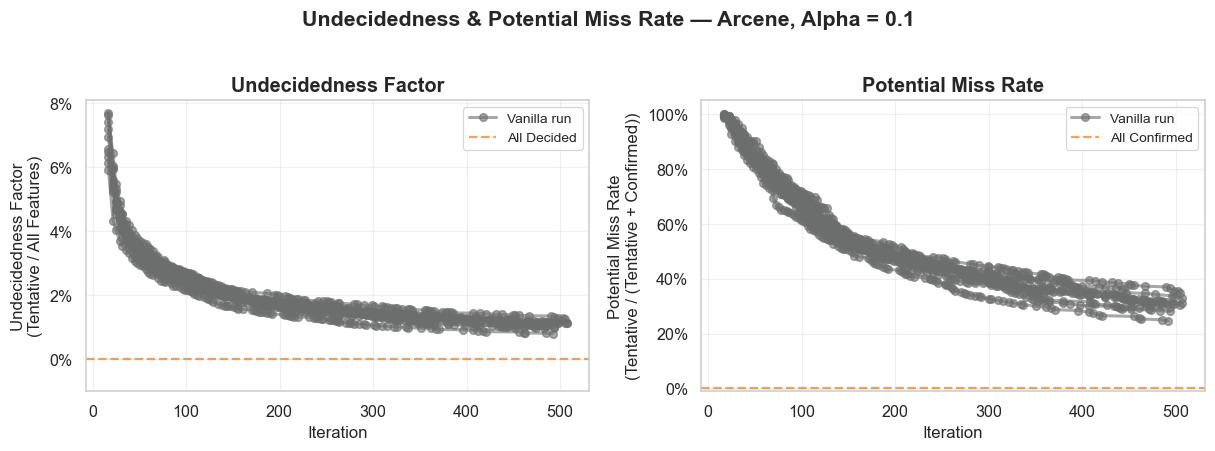

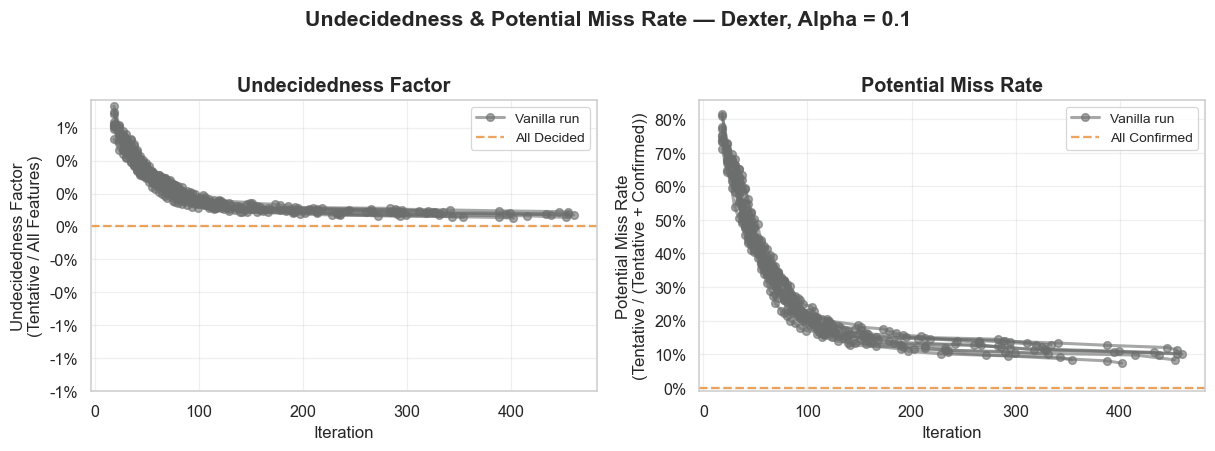

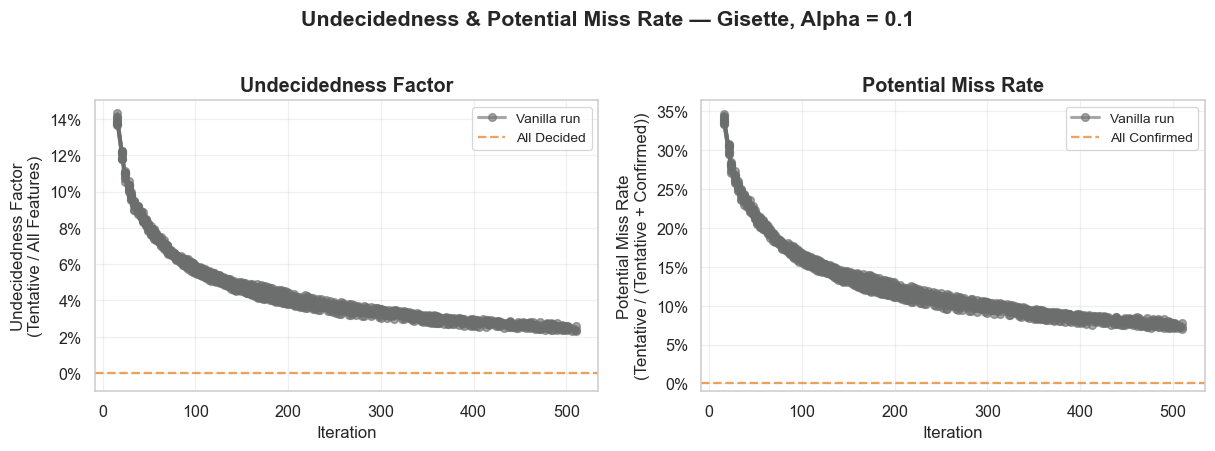

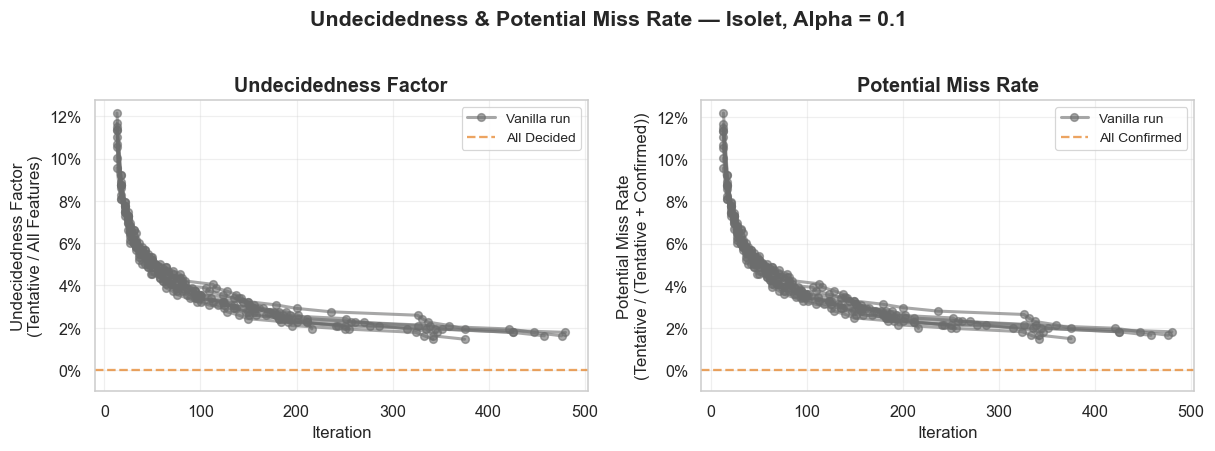

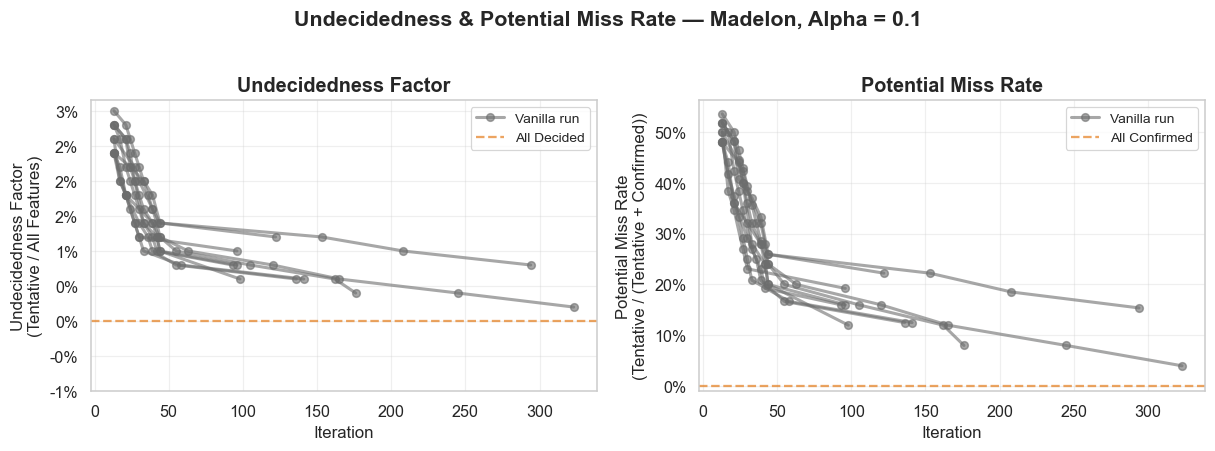

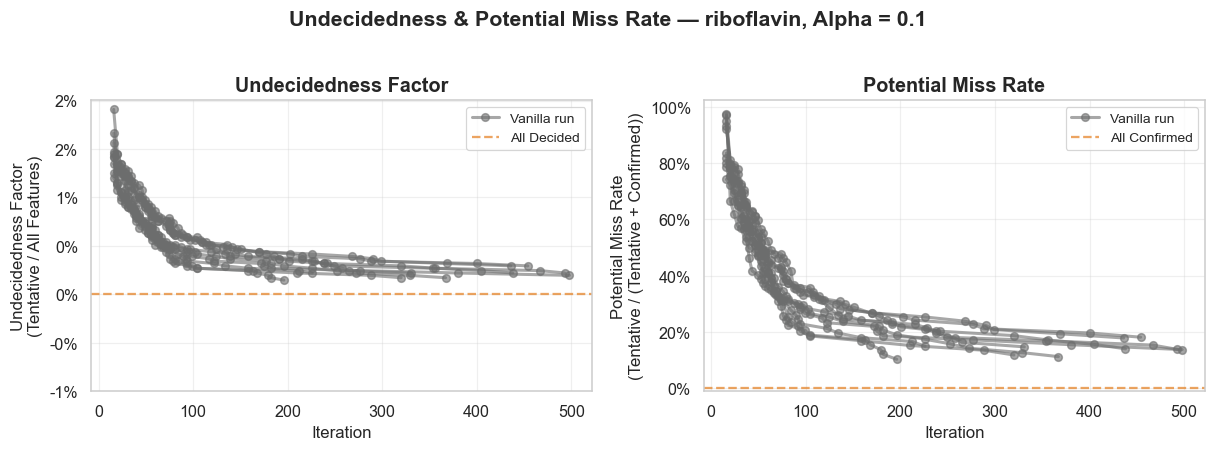

In [20]:

for dataset in datasets:
    ar.plot_undecidedness_single_alpha(
        dataset=dataset,
        estimator=TARGET_ESTIMATOR,
        df_checkpoints=df_checkpoints,
        alpha=0.1,              # the alpha to focus on
        x_axis="iteration",      # or "time"
        figures_dir=figures_dir,
    )

## 13. Statistical Equivalence Tests

Mann-Whitney U test for each (dataset, alpha, checkpoint) against the Greedy distribution.
A checkpoint is **equivalent** when `p > 0.05` (two-sided).

In [21]:
df_tests = ar.run_checkpoint_equivalence_tests(
    df_checkpoints=df_checkpoints,
    df_greedy=df_greedy,
    datasets=datasets,
    alphas=alphas,
    significance_level=0.05,
)

print(f'Statistical tests performed: {len(df_tests)}')
display_cols = [
    'Dataset', 'Alpha', 'Checkpoint_ID', 'Iteration',
    'N_Confirmed', 'Checkpoint_Mean', 'Greedy_Mean',
    'Diff', 'P_Value_MW', 'Is_Equivalent',
]
display(df_tests[display_cols].round(4))

Statistical tests performed: 1126


,Dataset,Alpha,Checkpoint_ID,Iteration,N_Confirmed,Checkpoint_Mean,Greedy_Mean,Diff,P_Value_MW,Is_Equivalent
0,Arcene,0.0,0,1,0.0000,0.0000,0.8746,-0.8746,0.0001,False
1,Arcene,0.0,1,30,0.5000,0.2750,0.8746,-0.5996,0.0001,False
2,Arcene,0.0,2,36,1.1000,0.4809,0.8746,-0.3937,0.0002,False
3,Arcene,0.0,3,40,5.6000,0.6439,0.8746,-0.2307,0.0002,False
4,Arcene,0.0,4,44,10.6000,0.7449,0.8746,-0.1297,0.0002,False
...,...,...,...,...,...,...,...,...,...,...
1121,riboflavin,0.1,27,249,51.5556,0.5443,0.5806,-0.0364,0.3074,True
1122,riboflavin,0.1,28,354,52.1667,0.5633,0.5806,-0.0173,0.7128,True
1123,riboflavin,0.1,29,467,52.6000,0.5674,0.5806,-0.0132,0.7679,True
1124,riboflavin,0.1,30,493,54.2500,0.5615,0.5806,-0.0192,0.6354,True


## 14. Minimum Iterations for Statistical Equivalence

For each (dataset, alpha), find the earliest checkpoint that is statistically
equivalent to Greedy.

In [22]:
df_min_equiv = ar.find_minimum_equivalence(
    df_tests=df_tests,
    df_greedy=df_greedy,
    datasets=datasets,
    alphas=alphas,
)

print('\n' + '=' * 80)
print('MINIMUM ITERATIONS FOR STATISTICAL EQUIVALENCE')
print('=' * 80)
display(df_min_equiv.round(4))


MINIMUM ITERATIONS FOR STATISTICAL EQUIVALENCE


,Dataset,Alpha,Min_Iter_Equiv,Time_To_Equiv,Greedy_Time,Time_Ratio,N_Confirmed_At_Equiv,Score_At_Equiv,Greedy_Score,P_Value
0,Arcene,0.000,87,78.3720,19.8673,3.9448,59.1,0.8578,0.8746,0.0640
1,Arcene,0.001,86,67.8785,13.9593,4.8626,76.5,0.8582,0.8745,0.0757
2,Arcene,0.100,45,41.8618,11.2435,3.7232,56.7,0.8553,0.8680,0.1212
3,Dexter,0.000,45,112.0939,34.0803,3.2891,49.6,0.9303,0.9368,0.0890
4,Dexter,0.001,34,89.7326,29.1572,3.0775,49.3,0.9306,0.9363,0.2123
5,Dexter,0.100,23,64.0578,20.9587,3.0564,50.2,0.9325,0.9351,0.5205
6,Gisette,0.000,29,96.4768,61.4540,1.5699,1287.6,0.9822,0.9821,0.9698
7,Gisette,0.001,23,76.8059,49.7805,1.5429,1315.1,0.9824,0.9821,0.2730
8,Gisette,0.100,16,57.1401,35.3919,1.6145,1355.8,0.9825,0.9824,0.8501
9,Isolet,0.000,26,21.2433,9.2647,2.2929,535.5,0.9587,0.9592,0.4727


## 15. Summary Statistics

In [23]:
ar.print_equivalence_summary(df_min_equiv)


SUMMARY STATISTICS

Configurations achieving equivalence: 18 / 18
Average iterations to equivalence : 42.2
Median  iterations to equivalence : 33.0
Average time to equivalence       : 55.94s
Average Greedy time               : 28.12s
Average time ratio (Vanilla/Greedy): 2.53x
Median  time ratio                : 2.54x

--------------------------------------------------------------------------------
By Dataset:
--------------------------------------------------------------------------------


,Min_Iter_mean,Min_Iter_std,Time_To_Equiv_mean,Time_To_Equiv_std,Time_Ratio_mean,Time_Ratio_std
Dataset,,,,,,
Arcene,72.67,23.97,62.70,18.80,4.18,0.60
Dexter,34.00,11.00,88.63,24.04,3.14,0.13
Gisette,22.67,6.51,76.81,19.67,1.58,0.04
Isolet,19.67,6.51,15.45,5.69,2.10,0.19
Madelon,32.00,11.00,9.63,3.04,2.95,0.16
riboflavin,72.00,22.52,82.44,26.12,1.24,0.04


## 16. Equivalence Visualization

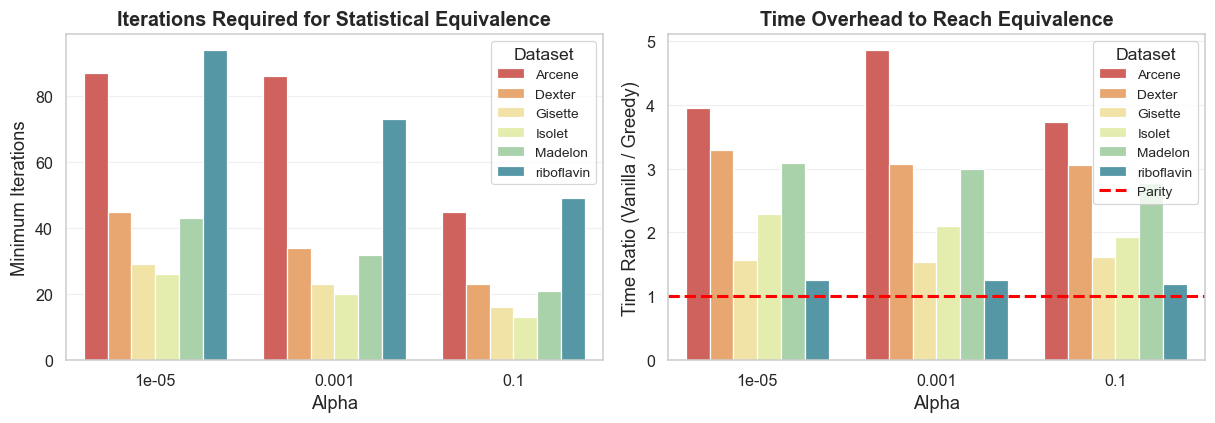

In [24]:
ar.plot_equivalence(df_min_equiv, figures_dir=figures_dir)

## 17. Key Findings

In [25]:
ar.print_key_findings(
    df_viz=df_viz,
    df_min_equiv=df_min_equiv,
    significance_level=0.1,
)


KEY FINDINGS

1. SCORE COMPARISON (Greedy vs Vanilla Strict)
   Tie: 9 configuration(s)
   Vanilla: 5 configuration(s)
   Greedy: 4 configuration(s)

2. AVERAGE SPEEDUP: 17.4x  (Vanilla time / Greedy time)

3. CONVERGENCE SPEED
   Vanilla reaches Greedy equivalence in 42.2 iterations on average
   Taking 2.5x Greedy time (median)

4. FASTEST CONVERGENCE
   Dataset=Isolet, Alpha=0.1, Iterations=13, Time=9.88s

5. SLOWEST CONVERGENCE
   Dataset=riboflavin, Alpha=1e-05, Iterations=94, Time=109.02s



## 18. Export Results

In [26]:
if CHECKPOINT_TESTS_PATH and CHECKPOINT_EQUIV_PATH:
    ar.export_results(
        df_tests=df_tests,
        df_min_equiv=df_min_equiv,
        tests_path=CHECKPOINT_TESTS_PATH,
        equiv_path=CHECKPOINT_EQUIV_PATH,
    )
else:
    print('Export skipped (paths set to None).')

Exported:
  ../data/checkpoint_statistical_tests.csv
  ../data/checkpoint_equivalence_summary.csv
